# Лабораторная работа 2. Классификация. Нейронные сети

**Выполнил:** Гладышев Р.М.  
**Проверил:** Антонянц Е.Н.  
**Датасет:** Water Quality / Water Potability (Kaggle) — пригодность воды для питья по физико-химическим показателям.  
**Задача:** бинарная классификация: по девяти показателям качества воды предсказать целевую переменную `Potability` (1 — вода пригодна для питья, 0 — непригодна).  
**План работы:** выбор и подготовка датасета → разбиение выборки → пять методов классификации (наивный Байес, дерево решений, LDA, SVM, kNN) с подбором гиперпараметров → нейронная сеть на TensorFlow с мониторингом в TensorBoard → сравнительный анализ по метрикам Accuracy, Precision, Recall, F1 и AUC-ROC → заключение.


## Введение

**Цель работы** — изучить методы классификации, реализованные в библиотеке Scikit-Learn, а также познакомиться с нейронными сетями на основе библиотек TensorFlow и TensorBoard.

**Задачи:**

1. выбрать и подготовить датасет для классификации (первичный анализ, заполнение пропусков, масштабирование);
2. разбить данные на обучающую и тестовую выборки (`train_test_split`) и зафиксировать случайные числа (seed) для воспроизводимости;
3. построить классификаторы пятью методами: наивный Байес (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, линейный дискриминантный анализ, метод опорных векторов, метод ближайших соседей;
4. настроить гиперпараметры каждого метода и исследовать их влияние на качество;
5. построить нейронную сеть на TensorFlow/Keras, провести эксперименты с числом эпох, размером батча, числом слоёв и нейронов, функциями активации, оптимизаторами и регуляризацией, следить за обучением в TensorBoard;
6. сравнить все методы по Accuracy, Precision, Recall, F1-score и AUC-ROC (столбчатые диаграммы и ROC-кривые) и обосновать выбор лучшего подхода.

Все преобразования (заполнение пропусков, масштабирование) выполняются внутри `Pipeline` и обучаются только на обучающей выборке, а гиперпараметры подбираются кросс-валидацией на обучающей выборке: тестовая выборка используется только для итоговой оценки.

In [1]:
import os, random, time, shutil, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     validation_curve, cross_val_score, cross_val_predict, cross_validate)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEED = 42                                   # единое зерно для воспроизводимости
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
print("scikit-learn / TensorFlow:", __import__("sklearn").__version__, "/", tf.__version__)

scikit-learn / TensorFlow: 1.9.1 / 2.21.0


**Пояснение к блоку кода.** Подключаем библиотеки: `pandas`, `numpy`, `scipy` — данные и статистика; `matplotlib`, `seaborn` — графики; `scikit-learn` — разбиение выборки, конвейеры, кросс-валидация, все пять семейств классификаторов и метрики; `tensorflow.keras` — нейронная сеть. Константа `SEED = 42` и вызовы `random.seed`, `np.random.seed`, `tf.keras.utils.set_random_seed` фиксируют случайные числа во всех библиотеках, чтобы эксперименты воспроизводились (требование задания). Предупреждения и служебные сообщения TensorFlow отключены, настроен единый формат вывода чисел.

## 1. Выбор и подготовка датасета

In [2]:
DATA_PATH = "water_potability.csv"
TARGET = "Potability"
df = pd.read_csv(DATA_PATH)
FEATURES = [c for c in df.columns if c != TARGET]

print("Размер таблицы (строки, столбцы):", df.shape)
df.info()
miss = df.isna().sum().to_frame("пропусков")
miss["доля, %"] = miss["пропусков"] / len(df) * 100
print("\nПропуски по столбцам:")
display(miss.T)
print("Полных дубликатов строк:", df.duplicated().sum())
print("\nРаспределение классов целевой переменной:")
display(df[TARGET].value_counts().to_frame("количество").assign(**{"доля, %": df[TARGET].value_counts(normalize=True) * 100}))
df.head()

Размер таблицы (строки, столбцы): (3276, 10)
<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB

Пропуски по столбцам:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
пропусков,491.0000,0.0000,0.0000,0.0000,781.0000,0.0000,0.0000,162.0000,0.0000,0.0000
"доля, %",14.9878,0.0000,0.0000,0.0000,23.8400,0.0000,0.0000,4.9451,0.0000,0.0000


Полных дубликатов строк: 0

Распределение классов целевой переменной:


,количество,"доля, %"
Potability,,
0,1998,60.9890
1,1278,39.0110


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.8905,"20,791.3190",7.3002,368.5164,564.3087,10.3798,86.9910,2.9631,0
1,3.7161,129.4229,"18,630.0579",6.6352,NaN,592.8854,15.1800,56.3291,4.5007,0
2,8.0991,224.2363,"19,909.5417",9.2759,NaN,418.6062,16.8686,66.4201,3.0559,0
3,8.3168,214.3734,"22,018.4174",8.0593,356.8861,363.2665,18.4365,100.3417,4.6288,0
4,9.0922,181.1015,"17,978.9863",6.5466,310.1357,398.4108,11.5583,31.9980,4.0751,0


**Пояснение к блоку кода.** Загружаем данные, формируем список признаков и выводим сведения о таблице: размер, типы столбцов (`info`), число и долю пропусков, число дубликатов и распределение классов. Это первичный анализ: он показывает, нужна ли очистка и насколько сбалансирована целевая переменная.

**Вывод.** В таблице 3 276 строк и 10 столбцов, все признаки вещественные. Пропуски есть только в `ph` (491), `Sulfate` (781) и `Trihalomethanes` (162). Дубликатов нет. Классов два: 1 998 образцов непригодной воды (61.0%) и 1 278 пригодной (39.0%) — умеренный дисбаланс.

## Описание датасета

**Water Potability** — набор данных о качестве воды: **3 276 образцов**, **9 числовых признаков** (физико-химические показатели) и бинарная целевая переменная **`Potability`**.

| Признак | Описание | Единицы |
|---|---|---|
| `ph` | водородный показатель (кислотность воды) | 0–14 |
| `Hardness` | жёсткость воды (содержание солей кальция и магния) | мг/л |
| `Solids` | общее количество растворённых твёрдых веществ (TDS) | ppm |
| `Chloramines` | содержание хлораминов (дезинфицирующие вещества) | ppm |
| `Sulfate` | содержание сульфатов | мг/л |
| `Conductivity` | удельная электропроводность | мкСм/см |
| `Organic_carbon` | общий органический углерод | ppm |
| `Trihalomethanes` | тригалометаны (побочные продукты хлорирования) | мкг/л |
| `Turbidity` | мутность | NTU |
| **`Potability`** | **целевая переменная: 1 — вода пригодна для питья, 0 — нет** | класс |

Выбранная задача — **бинарная классификация**. Положительным классом считается **1 (пригодная вода)**: именно по нему вычисляются Precision, Recall и F1. Классы **умеренно несбалансированы**: непригодной воды 61.0% (1 998 образцов), пригодной — 39.0% (1 278). Поэтому доля правильных ответов тривиального классификатора, всегда отвечающего «непригодна», уже равна **0.610** — это нижняя планка для Accuracy, которую любой полезный метод должен превзойти; при этом AUC-ROC тривиального классификатора равна 0.5.

**Пропуски.** Три признака содержат пропуски: `ph` — 491 (15.0%), `Sulfate` — 781 (23.8%), `Trihalomethanes` — 162 (4.9%). Всего 1 265 строк (38.6%) имеют хотя бы один пропуск; удаление таких строк оставило бы лишь 2 011 образцов, поэтому пропуски заполняются, а не удаляются. Полных дубликатов нет.

In [3]:
desc = df.describe().T
desc["skew"] = df.skew()
desc

,count,mean,std,min,25%,50%,75%,max,skew
ph,"2,785.0000",7.0808,1.5943,0.0000,6.0931,7.0368,8.0621,14.0000,0.0256
Hardness,"3,276.0000",196.3695,32.8798,47.4320,176.8505,196.9676,216.6675,323.1240,-0.0393
Solids,"3,276.0000","22,014.0925","8,768.5708",320.9426,"15,666.6903","20,927.8336","27,332.7621","61,227.1960",0.6216
Chloramines,"3,276.0000",7.1223,1.5831,0.3520,6.1274,7.1303,8.1149,13.1270,-0.0121
Sulfate,"2,495.0000",333.7758,41.4168,129.0000,307.6995,333.0735,359.9502,481.0306,-0.0359
Conductivity,"3,276.0000",426.2051,80.8241,181.4838,365.7344,421.8850,481.7923,753.3426,0.2645
Organic_carbon,"3,276.0000",14.2850,3.3082,2.2000,12.0658,14.2183,16.5577,28.3000,0.0255
Trihalomethanes,"3,114.0000",66.3963,16.1750,0.7380,55.8445,66.6225,77.3375,124.0000,-0.0830
Turbidity,"3,276.0000",3.9668,0.7804,1.4500,3.4397,3.9550,4.5003,6.7390,-0.0078
Potability,"3,276.0000",0.3901,0.4878,0.0000,0.0000,0.0000,1.0000,1.0000,0.4508


**Пояснение к блоку кода.** Метод `describe()` вычисляет для каждого признака число непустых значений, среднее, стандартное отклонение, минимум, квартили и максимум; добавлен коэффициент асимметрии. Таблица нужна, чтобы оценить масштабы признаков и проверить правдоподобие значений.

**Вывод.** Масштабы различаются на порядки: `Solids` — в среднем 22 014 (до 61 227), `Conductivity` ≈ 426, `Sulfate` ≈ 334, `Hardness` ≈ 196, а `ph`, `Chloramines`, `Turbidity`, `Trihalomethanes` и `Organic_carbon` — единицы и десятки. Поэтому для SVM, kNN, LDA и нейросети признаки нужно стандартизовать. Асимметрия почти у всех признаков близка к нулю (распределения близки к нормальным); умеренно скошен вправо только `Solids` (0.62). Значения `ph` лежат в допустимом диапазоне 0–14.

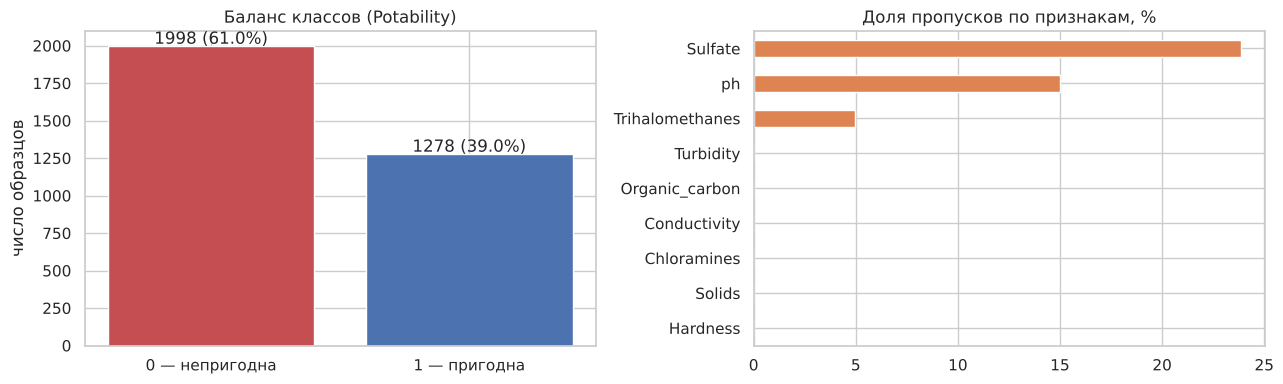

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cnt = df[TARGET].value_counts().sort_index()
axes[0].bar(["0 — непригодна", "1 — пригодна"], cnt.values, color=["#C44E52", "#4C72B0"])
for i, v in enumerate(cnt.values):
    axes[0].text(i, v + 15, f"{v} ({v/len(df):.1%})", ha="center")
axes[0].set_title("Баланс классов (Potability)"); axes[0].set_ylabel("число образцов")
miss_pct = (df[FEATURES].isna().mean() * 100).sort_values()
miss_pct.plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("Доля пропусков по признакам, %")
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Слева — столбчатая диаграмма числа образцов в каждом классе с подписью доли, справа — доля пропусков по признакам. Первый график показывает баланс классов (от него зависит выбор метрик), второй — масштаб проблемы пропусков.

**Вывод по графикам.** Слева: преобладает класс 0 (61%), класс 1 составляет 39% — дисбаланс умеренный, поэтому Accuracy нужно сравнивать с долей большего класса (0.61) и обязательно смотреть Precision, Recall, F1 и AUC. Справа: больше всего пропусков у `Sulfate` (≈ 24%), затем `ph` (≈ 15%) и `Trihalomethanes` (≈ 5%); остальные шесть признаков заполнены полностью.

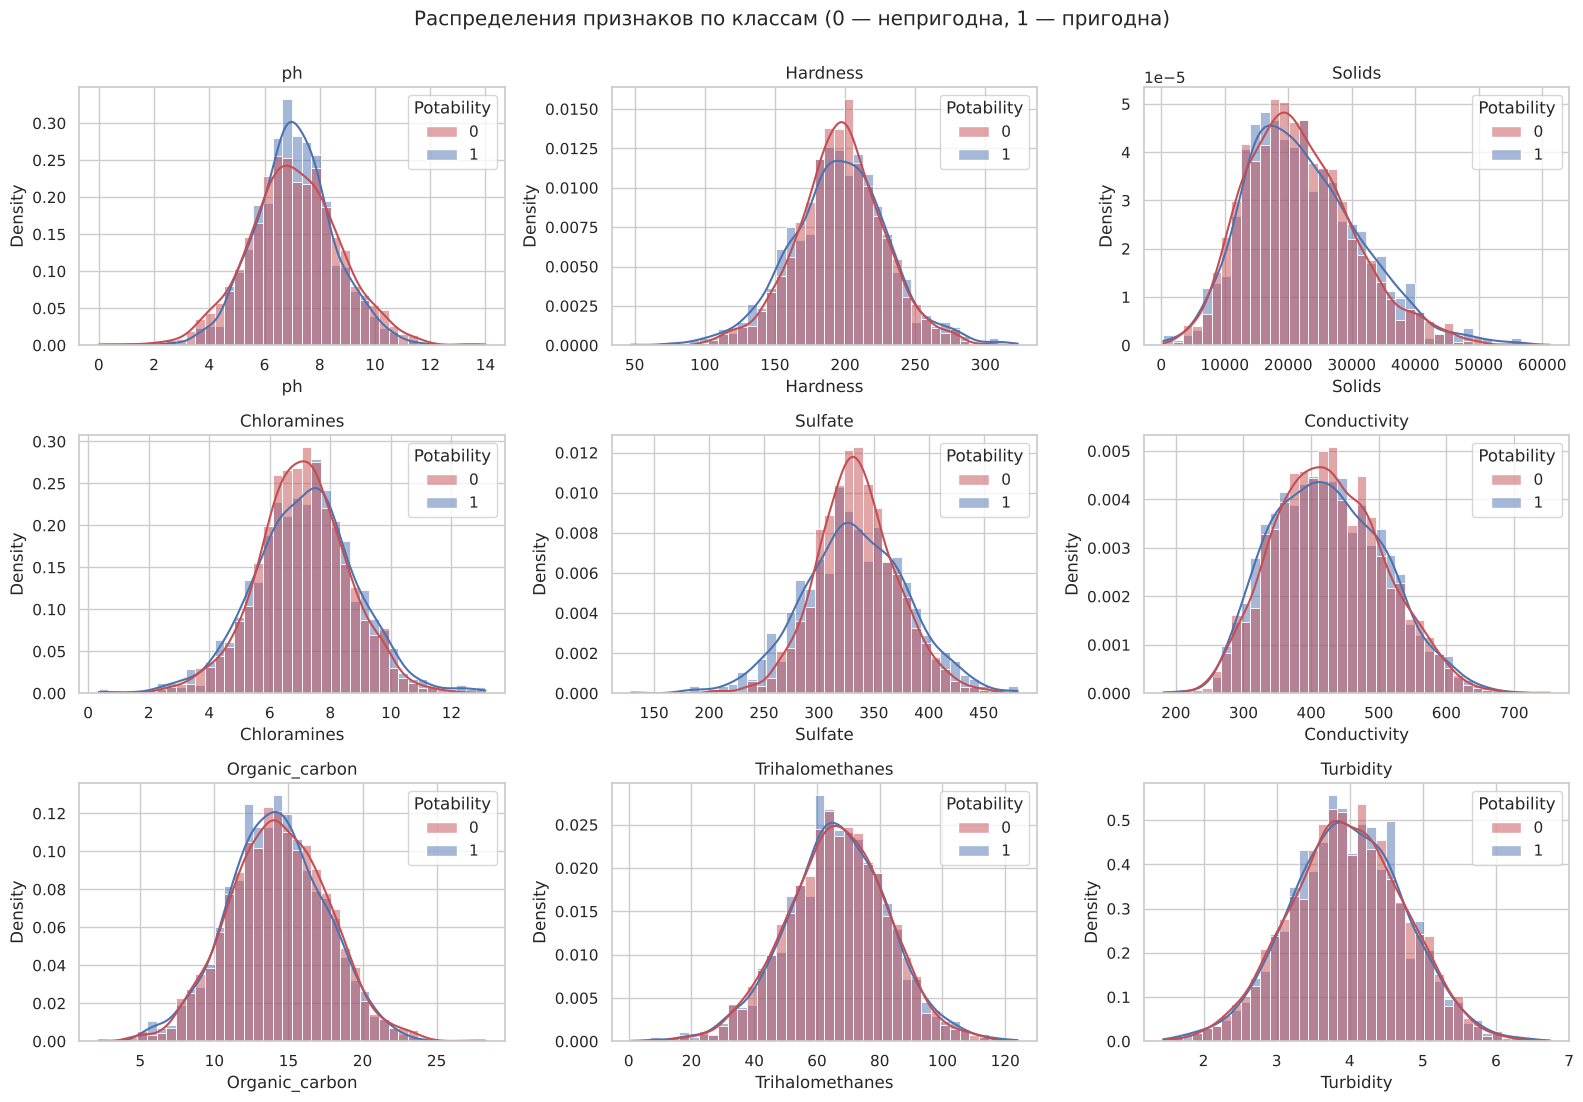

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, stat="density", common_norm=False,
                 palette=["#C44E52", "#4C72B0"], ax=ax, bins=40)
    ax.set_title(col)
plt.suptitle("Распределения признаков по классам (0 — непригодна, 1 — пригодна)", y=1.0)
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Для каждого признака строим гистограммы с оценкой плотности (KDE) отдельно для двух классов; по оси Y откладывается плотность (`common_norm=False`), чтобы классы разного размера были сопоставимы. Цель — увидеть, различаются ли распределения признаков у пригодной и непригодной воды: если различаются, признак информативен.

**Вывод по графикам.** Распределения признаков почти симметричны и имеют форму колокола. Но кривые двух классов **практически совпадают** по положению: средние значения признаков в классах не различаются. Отличия касаются лишь формы: у класса 1 распределения чуть «шире» (например, у `Sulfate`, `Chloramines`, `Hardness`: больше доля значений в хвостах), а у класса 0 — выше в центре; у `ph` наоборот: класс 1 более сосредоточен около нейтрального значения 7, а у класса 0 хвосты тяжелее. Таким образом, по одному признаку классы разделить практически невозможно — это важнейшая особенность датасета, объясняющая все результаты ниже.

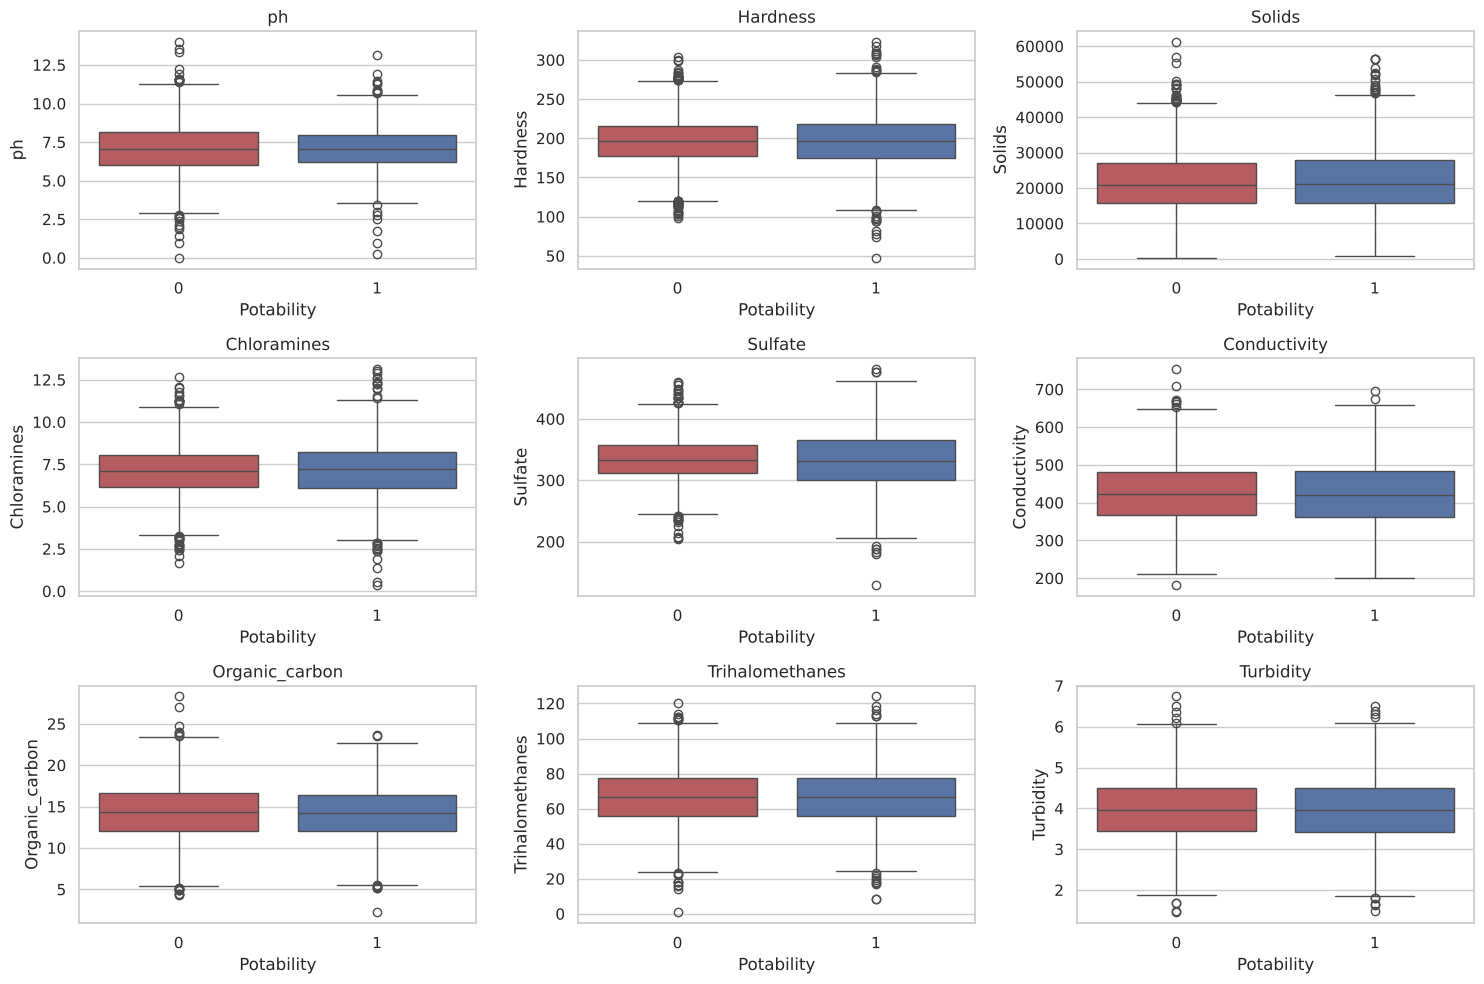

,выбросов (1.5·IQR),"доля, %",среднее (класс 0),среднее (класс 1),p-value (Манн–Уитни)
признак,,,,,
ph,46,1.6517,7.0854,7.0738,0.9084
Hardness,83,2.5336,196.7333,195.8007,0.5439
Solids,47,1.4347,"21,777.4908","22,383.9910",0.1333
Chloramines,61,1.8620,7.0922,7.1693,0.1529
Sulfate,41,1.6433,334.5643,332.5670,0.4050
Conductivity,11,0.3358,426.7305,425.3838,0.5523
Organic_carbon,25,0.7631,14.3643,14.1609,0.1255
Trihalomethanes,33,1.0597,66.3036,66.5397,0.7672
Turbidity,19,0.5800,3.9658,3.9683,0.9504


In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=["#C44E52", "#4C72B0"], legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

rows = []
for col in FEATURES:
    s = df[col].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    n_out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    a, b = df.loc[df[TARGET] == 0, col].dropna(), df.loc[df[TARGET] == 1, col].dropna()
    rows.append({"признак": col, "выбросов (1.5·IQR)": n_out, "доля, %": n_out / len(s) * 100,
                 "среднее (класс 0)": a.mean(), "среднее (класс 1)": b.mean(),
                 "p-value (Манн–Уитни)": stats.mannwhitneyu(a, b).pvalue})
pd.DataFrame(rows).set_index("признак")

**Пояснение к блоку кода.** Диаграммы размаха по классам показывают медиану, межквартильный размах и выбросы каждого признака в двух классах. Далее для каждого признака подсчитывается число выбросов по правилу 1.5·IQR, средние значения по классам и p-value критерия Манна–Уитни — непараметрической проверки гипотезы о том, что значения в двух классах распределены одинаково.

**Вывод.** «Ящики» двух классов практически совпадают для всех девяти признаков. Выбросов немного: от 11 (`Conductivity`, 0.3%) до 83 (`Hardness`, 2.5%). Средние по классам почти равны (например, `ph` 7.085 и 7.074), а p-value у **всех** признаков больше 0.05 (от 0.126 до 0.950), то есть статистически значимых различий между классами по отдельным признакам нет. Информация о классе, если она есть, содержится не в отдельных признаках, а в их сочетаниях.

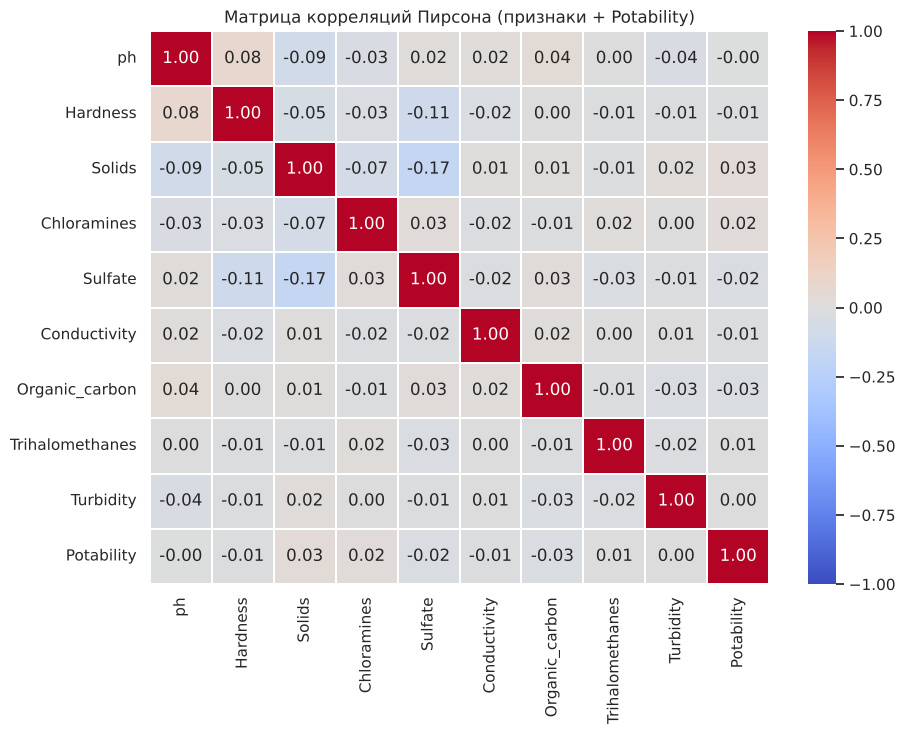

Корреляция признаков с целевой переменной:


,r
Solids,0.0337
Organic_carbon,-0.0300
Chloramines,0.0238
Sulfate,-0.0236
Hardness,-0.0138
Conductivity,-0.0081
Trihalomethanes,0.0071
ph,-0.0036
Turbidity,0.0016


Наибольшая |корреляция| между признаками: 0.172

Доля пригодной воды (Potability = 1) среди строк с пропуском и без:


,пропуск есть,пропуска нет
ph,0.3605,0.3953
Sulfate,0.3752,0.3948
Trihalomethanes,0.3395,0.3927


In [7]:
corr = df.corr()
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=.3)
plt.title("Матрица корреляций Пирсона (признаки + Potability)")
plt.tight_layout(); plt.show()

print("Корреляция признаков с целевой переменной:")
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("r"))
print("Наибольшая |корреляция| между признаками:",
      corr.drop(index=TARGET, columns=TARGET).where(~np.eye(len(FEATURES), dtype=bool)).abs().max().max().round(3))

print("\nДоля пригодной воды (Potability = 1) среди строк с пропуском и без:")
pd.DataFrame({c: {"пропуск есть": df.loc[df[c].isna(), TARGET].mean(), "пропуска нет": df.loc[df[c].notna(), TARGET].mean()}
              for c in ["ph", "Sulfate", "Trihalomethanes"]}).T

**Пояснение к блоку кода.** Строим матрицу корреляций Пирсона между всеми признаками и целевой переменной (тепловая карта), выводим корреляции признаков с `Potability` по убыванию модуля, максимальную корреляцию между признаками, а также долю пригодной воды среди строк с пропуском и без пропуска (проверка, не несёт ли сам факт пропуска информации).

**Вывод.** Корреляции признаков с целью ничтожны: максимальная — `Solids` (0.034), остальные по модулю меньше 0.03. Корреляции **между признаками** тоже малы (максимум 0.17), то есть признаки практически независимы: мультиколлинеарности нет. Низкие линейные связи означают, что линейные методы (LDA, линейный SVM) будут близки к случайному угадыванию. Доля пригодной воды при пропуске чуть ниже (34–38%), чем без него (39–40%), но разница невелика, и заполнение медианой допустимо.

In [8]:
print("Проверка физической допустимости значений:")
print("  ph вне диапазона [0, 14]:", ((df["ph"] < 0) | (df["ph"] > 14)).sum())
print("  отрицательные значения (любой признак):", (df[FEATURES] < 0).sum().sum())
print("  нулевые значения по признакам:", (df[FEATURES] == 0).sum().to_dict())
print("  строк с хотя бы одним пропуском:", df[FEATURES].isna().any(axis=1).sum(), f"({df[FEATURES].isna().any(axis=1).mean():.1%})")
print("  строк без пропусков (осталось бы при dropna):", df.dropna().shape[0])

Проверка физической допустимости значений:
  ph вне диапазона [0, 14]: 0
  отрицательные значения (любой признак): 0
  нулевые значения по признакам: {'ph': 1, 'Hardness': 0, 'Solids': 0, 'Chloramines': 0, 'Sulfate': 0, 'Conductivity': 0, 'Organic_carbon': 0, 'Trihalomethanes': 0, 'Turbidity': 0}
  строк с хотя бы одним пропуском: 1265 (38.6%)
  строк без пропусков (осталось бы при dropna): 2011


**Пояснение к блоку кода.** Проверяем физическую допустимость значений (`ph` вне [0, 14], отрицательные значения, нули) и считаем, сколько строк содержит пропуски и сколько останется после удаления таких строк.

**Вывод.** Недопустимых значений нет (единственный нуль — `ph` = 0, физически возможное предельное значение). Пропуски есть в 1 265 строках (38.6%), удаление строк с пропусками оставило бы лишь 2 011 образцов, поэтому выбрано заполнение медианой.

## Подготовка данных

**Принятые решения по предобработке:**

1. **Пропуски.** Заполняются **медианой** признака (`SimpleImputer(strategy="median")`). Медиана выбрана, потому что она устойчива к выбросам, а доля пропусков невелика; пропуски не связаны с целевой переменной (доля пригодной воды среди строк с пропуском и без неё почти одинакова: 34–38% против 39–40%), то есть «пропуск» не несёт полезной информации. Заполнение выполняется **внутри конвейера**, и медиана вычисляется только по обучающей части — это исключает утечку информации из тестовой выборки.
2. **Выбросы.** Доля выбросов по правилу 1.5·IQR невелика (0.3–2.5% по признакам); все значения физически допустимы (`ph` в пределах 0–14, отрицательных значений нет), поэтому выбросы **не удаляются**: это реальные, хотя и редкие, образцы воды.
3. **Масштабирование.** Масштабы признаков различаются на 4 порядка (`Solids` порядка 22 000, `ph` порядка 7, `Turbidity` порядка 4), а SVM, kNN, LDA и нейронная сеть чувствительны к масштабу, поэтому признаки **стандартизируются** (`StandardScaler`). Для MultinomialNB и ComplementNB, которые принимают только неотрицательные значения, используется нормализация `MinMaxScaler` в диапазон [0, 1]. Дерево решений от масштаба не зависит.
4. **Кодирование.** Категориальных признаков нет, кодирование не требуется. Целевая переменная уже бинарная (0/1).

## 2. Разбиение выборки

In [9]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Обучающая выборка:", X_train.shape, "| тестовая:", X_test.shape)
print("Доля класса 1: train = {:.3f}, test = {:.3f}, вся выборка = {:.3f}".format(y_train.mean(), y_test.mean(), y.mean()))
print("Пропусков в train:", X_train.isna().sum().sum(), "| в test:", X_test.isna().sum().sum())
print("Медианы признаков по обучающей выборке (будут использованы для заполнения пропусков):")
X_train.median().to_frame("медиана").T

Обучающая выборка: (2620, 9) | тестовая: (656, 9)
Доля класса 1: train = 0.390, test = 0.390, вся выборка = 0.390
Пропусков в train: 1146 | в test: 288
Медианы признаков по обучающей выборке (будут использованы для заполнения пропусков):


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
медиана,7.0350,196.9281,"20,866.3358",7.1182,333.0735,424.9413,14.2148,66.5657,3.9696


**Пояснение к блоку кода.** Формируем матрицу признаков `X` и вектор цели `y` и делим данные функцией `train_test_split` в пропорции 80/20 со **стратификацией** (`stratify=y`: доля класса 1 сохраняется в обеих частях) и фиксированным `random_state`. Печатаем размеры, доли классов и число пропусков, а также медианы признаков по обучающей выборке (они будут использованы для заполнения пропусков и в обучающей, и в тестовой частях).

**Вывод.** Получено 2 620 обучающих и 656 тестовых образцов; доля класса 1 одинакова в обеих частях и во всём наборе (0.390). Пропуски распределены между частями пропорционально (1 146 в обучении и 288 в тесте). Тестовая выборка откладывается и до итоговой оценки не используется.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_pipe(clf, scaler="standard"):
    """Конвейер: заполнение пропусков медианой -> масштабирование -> классификатор.
    Все шаги обучаются только на обучающей части каждого блока кросс-валидации."""
    sc = {"standard": StandardScaler(), "minmax": MinMaxScaler(), None: "passthrough"}[scaler]
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", sc), ("clf", clf)])

def get_scores(model, X_):
    """Оценка принадлежности к классу 1: вероятность, а если её нет - решающая функция."""
    return model.predict_proba(X_)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_)

def metrics_from(y_true, y_pred, score):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "AUC-ROC": roc_auc_score(y_true, score)}

def evaluate(model, X_, y_):
    return metrics_from(y_, model.predict(X_), get_scores(model, X_))

TUNED = {}

def tune(name, pipe, grid):
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True, return_train_score=True)
    gs.fit(X_train, y_train)
    TUNED[name] = gs
    print(f"{name}: лучший CV AUC = {gs.best_score_:.4f}  ({len(gs.cv_results_['params'])} комбинаций, {time.time()-t0:.1f} с)")
    print("   лучшие параметры:", {k.replace('clf__', ''): (float(v) if isinstance(v, np.floating) else v) for k, v in gs.best_params_.items()})
    return gs

dummy = make_pipe(DummyClassifier(strategy="most_frequent"), None).fit(X_train, y_train)
dummy_scores = pd.DataFrame([evaluate(dummy, X_test, y_test)], index=["Dummy (самый частый класс)"])
dummy_scores

,Accuracy,Precision,Recall,F1,AUC-ROC
Dummy (самый частый класс),0.6098,0.0000,0.0000,0.0000,0.5000


**Пояснение к блоку кода.** Здесь заданы общие инструменты для всех экспериментов: 5-кратная стратифицированная кросс-валидация `cv`; функция `make_pipe`, собирающая конвейер «заполнение медианой → масштабирование → классификатор»; функции вычисления метрик (Accuracy, Precision, Recall, F1, AUC-ROC) и оценки модели; функция `tune`, запускающая `GridSearchCV` по AUC-ROC и сохраняющая лучшую модель. Также построен тривиальный классификатор `DummyClassifier`, всегда предсказывающий самый частый класс, как нижний ориентир.

**Вывод.** Тривиальный классификатор имеет Accuracy 0.610 (доля класса 0), а Precision, Recall и F1 равны нулю (он никогда не предсказывает класс 1); AUC-ROC = 0.5. Любой полезный метод должен превзойти эти значения.

## 3. Методы классификации

Ниже кратко описаны используемые методы; подробности настройки и результаты — в следующем разделе.

**Наивный байесовский классификатор.** Опирается на теорему Байеса: класс выбирается по максимуму апостериорной вероятности P(c | x) ∝ P(c) · ∏ P(xⱼ | c). «Наивное» допущение — признаки условно независимы при известном классе. Варианты различаются моделью распределения P(xⱼ | c):

- **GaussianNB** — для каждого признака и класса предполагается нормальное распределение; гиперпараметр `var_smoothing` добавляет к дисперсиям малую долю максимальной дисперсии для устойчивости;
- **MultinomialNB** — частотная модель (для счётчиков, например слов), требует неотрицательных признаков; параметр `alpha` — сглаживание Лапласа/Лидстоуна;
- **ComplementNB** — модификация MultinomialNB для несбалансированных классов: оценивает параметры по дополнению класса;
- **BernoulliNB** — для бинарных признаков (есть/нет), непрерывные значения предварительно бинаризуются по порогу `binarize`.

Достоинства: быстрота и простота; недостатки: нереалистичное допущение независимости; для непрерывных данных пригоден в первую очередь GaussianNB.

**Дерево решений (Decision Tree).** Последовательно разбивает пространство признаков на области по условиям вида «признак ≤ порог», выбирая разбиение, которое максимально снижает неоднородность узла (критерии Джини или энтропия). Ключевые гиперпараметры: `max_depth` (глубина), `min_samples_leaf` (минимальное число образцов в листе) и `criterion`. Дерево легко интерпретируется и улавливает нелинейности и взаимодействия, но при большой глубине склонно к переобучению.

**Линейный дискриминантный анализ (LDA).** Предполагает, что внутри каждого класса признаки распределены нормально с **общей** ковариационной матрицей; тогда граница между классами — гиперплоскость. Гиперпараметры: решатель (`svd`, `lsqr`, `eigen`) и сжатие ковариационной матрицы `shrinkage`. Модель линейна: если данные нелинейно разделимы, она будет неэффективна.

**Метод опорных векторов (SVM).** Строит разделяющую гиперплоскость с максимальным зазором между классами; с помощью **ядерной функции** (линейное, полиномиальное, RBF, сигмоидное) неявно переходит в пространство большей размерности, что позволяет получить нелинейную границу. Гиперпараметры: `C` (штраф за ошибки: большое C — узкий зазор и риск переобучения), `gamma` (радиус влияния объекта у RBF), `degree` (степень полинома), тип ядра. Требует масштабирования признаков.

**Метод ближайших соседей (kNN).** Класс объекта определяется голосованием `k` ближайших к нему обучающих объектов. Гиперпараметры: `k` (мало соседей — переобучение, много — слишком гладкая граница), способ взвешивания (`uniform` или `distance`), метрика расстояния. Метод «ленивый» (обучения нет), чувствителен к масштабу признаков и к числу нерелевантных признаков.

**Нейронная сеть (многослойный перцептрон).** Последовательность полносвязных слоёв, в каждом из которых линейное преобразование сопровождается нелинейной функцией активации; для бинарной классификации на выходе стоит один нейрон с сигмоидой (вероятность класса 1), а функция потерь — бинарная перекрёстная энтропия. Веса обучаются градиентным спуском (оптимизаторы SGD, RMSprop, Adam). Подробно — в разделе 5.

**Метрики качества** (положительный класс — «вода пригодна»; TP, FP, TN, FN — элементы матрицы ошибок):

- **Accuracy** = (TP + TN) / N — доля верных ответов; при несбалансированных классах может вводить в заблуждение (тривиальный классификатор даёт 0.61);
- **Precision** = TP / (TP + FP) — из объявленных пригодными действительно пригодны;
- **Recall** = TP / (TP + FN) — какую долю по-настоящему пригодных образцов удалось найти;
- **F1** = 2 · Precision · Recall / (Precision + Recall) — их гармоническое среднее;
- **AUC-ROC** — площадь под кривой «доля истинно положительных — доля ложно положительных» при всевозможных порогах; не зависит от порога и баланса классов, 0.5 соответствует случайному угадыванию, 1.0 — идеальному разделению. Для подбора гиперпараметров используется именно AUC-ROC по 5-кратной стратифицированной кросс-валидации, поскольку она не привязана к выбору порога.

## 4. Настройка гиперпараметров

Для каждого метода гиперпараметры подбираются перебором по сетке (`GridSearchCV`) с **5-кратной стратифицированной кросс-валидацией** на обучающей выборке; критерий выбора — AUC-ROC. Для каждого метода строятся графики, показывающие, как гиперпараметры влияют на качество (на графиках «train (CV)» — качество на обучающих блоках, «validation (CV)» — на валидационных блоках; большой разрыв между ними означает переобучение).

### 4.1. Наивный байесовский классификатор

Исследуются все четыре варианта. Для GaussianNB меняется `var_smoothing`; для MultinomialNB и ComplementNB — сглаживание `alpha` (и `fit_prior` / `norm`); для BernoulliNB — порог бинаризации `binarize` (по стандартизованным признакам) и `alpha`. MultinomialNB и ComplementNB применяются к признакам, нормализованным в [0, 1] (`MinMaxScaler`).

In [11]:
nb_specs = {
    "GaussianNB": (make_pipe(GaussianNB(), "standard"),
                   {"clf__var_smoothing": np.logspace(-9, 0, 10)}),
    "MultinomialNB": (make_pipe(MultinomialNB(), "minmax"),
                      {"clf__alpha": np.logspace(-3, 2, 11), "clf__fit_prior": [True, False]}),
    "ComplementNB": (make_pipe(ComplementNB(), "minmax"),
                     {"clf__alpha": np.logspace(-3, 2, 11), "clf__norm": [True, False]}),
    "BernoulliNB": (make_pipe(BernoulliNB(), "standard"),
                    {"clf__binarize": [0.0, 0.25, 0.5, 0.75, 1.0, 1.5], "clf__alpha": [0.01, 0.1, 1.0, 10.0]}),
}
for name, (pipe, grid) in nb_specs.items():
    tune(name, pipe, grid)

nb_table = pd.DataFrame({n: {"лучшие параметры": {k.replace('clf__', ''): (float(f"{v:.3g}") if isinstance(v, (float, np.floating)) else v) for k, v in TUNED[n].best_params_.items()},
                             "CV AUC (лучший)": TUNED[n].best_score_,
                             "CV AUC (мин. по сетке)": TUNED[n].cv_results_["mean_test_score"].min()} for n in nb_specs}).T
nb_table

GaussianNB: лучший CV AUC = 0.5867  (10 комбинаций, 3.3 с)
   лучшие параметры: {'var_smoothing': 1e-09}


MultinomialNB: лучший CV AUC = 0.4945  (22 комбинаций, 1.5 с)
   лучшие параметры: {'alpha': 100.0, 'fit_prior': True}


ComplementNB: лучший CV AUC = 0.4945  (22 комбинаций, 1.7 с)
   лучшие параметры: {'alpha': 100.0, 'norm': False}


BernoulliNB: лучший CV AUC = 0.5533  (24 комбинаций, 2.3 с)
   лучшие параметры: {'alpha': 1.0, 'binarize': 1.0}


,лучшие параметры,CV AUC (лучший),CV AUC (мин. по сетке)
GaussianNB,{'var_smoothing': 1e-09},0.5867,0.5767
MultinomialNB,"{'alpha': 100.0, 'fit_prior': True}",0.4945,0.4829
ComplementNB,"{'alpha': 100.0, 'norm': False}",0.4945,0.4821
BernoulliNB,"{'alpha': 1.0, 'binarize': 1.0}",0.5533,0.4676


**Пояснение к блоку кода.** Для каждого из четырёх вариантов наивного Байеса запускается перебор гиперпараметров по сетке с 5-кратной кросс-валидацией по AUC-ROC. GaussianNB и BernoulliNB работают со стандартизованными признаками, MultinomialNB и ComplementNB — с признаками в [0, 1]. После подбора выводится сводная таблица: лучшие параметры, лучший и худший AUC по сетке.

**Вывод.** Качество наивного Байеса низкое: GaussianNB — CV AUC 0.587, BernoulliNB — 0.553, а MultinomialNB и ComplementNB — 0.495, то есть на уровне случайного угадывания (и даже чуть ниже 0.5). Причина: допущения этих моделей не подходят к данным — частотные модели Multinomial и Complement рассчитаны на счётчики, а на непрерывных нормализованных признаках не извлекают информации; Bernoulli теряет информацию при бинаризации; Gaussian предполагает различие средних по классам, а оно у нас отсутствует (см. EDA).

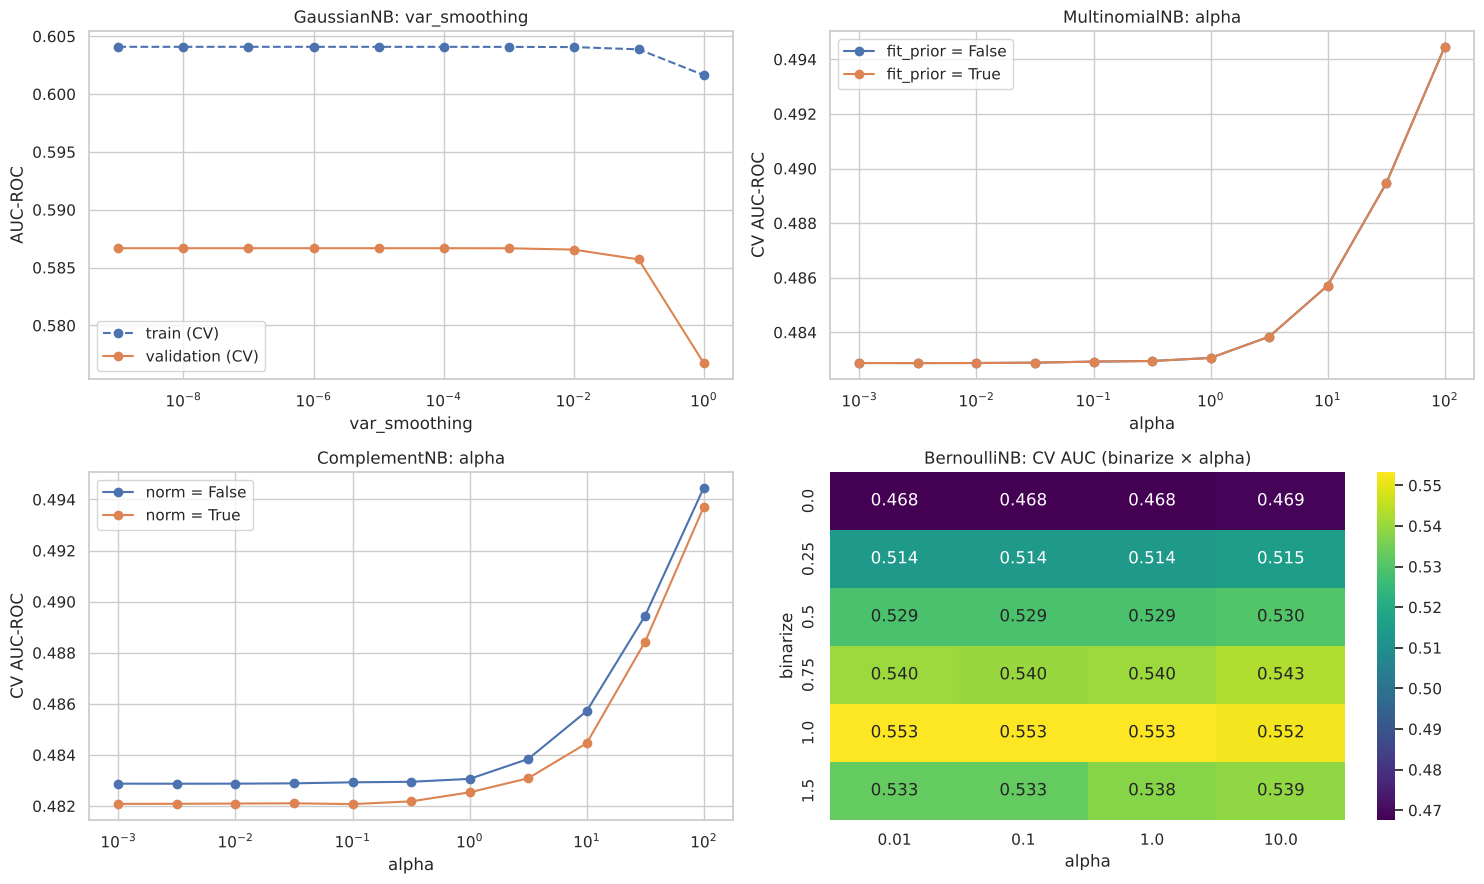

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
r = pd.DataFrame(TUNED["GaussianNB"].cv_results_)
ax = axes[0, 0]
ax.semilogx(r["param_clf__var_smoothing"].astype(float), r["mean_train_score"], "o--", label="train (CV)")
ax.semilogx(r["param_clf__var_smoothing"].astype(float), r["mean_test_score"], "o-", label="validation (CV)")
ax.set_title("GaussianNB: var_smoothing"); ax.set_xlabel("var_smoothing"); ax.set_ylabel("AUC-ROC"); ax.legend()

for ax, name, par in [(axes[0, 1], "MultinomialNB", "fit_prior"), (axes[1, 0], "ComplementNB", "norm")]:
    r = pd.DataFrame(TUNED[name].cv_results_)
    for val, g in r.groupby(f"param_clf__{par}"):
        ax.semilogx(g["param_clf__alpha"].astype(float), g["mean_test_score"], "o-", label=f"{par} = {val}")
    ax.set_title(f"{name}: alpha"); ax.set_xlabel("alpha"); ax.set_ylabel("CV AUC-ROC"); ax.legend()

r = pd.DataFrame(TUNED["BernoulliNB"].cv_results_)
piv = r.pivot_table(index="param_clf__binarize", columns="param_clf__alpha", values="mean_test_score")
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=axes[1, 1])
axes[1, 1].set_title("BernoulliNB: CV AUC (binarize × alpha)"); axes[1, 1].set_xlabel("alpha"); axes[1, 1].set_ylabel("binarize")
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Четыре графика показывают влияние гиперпараметров наивного Байеса на AUC-ROC: GaussianNB — `var_smoothing` (кривые для обучающих и валидационных блоков), MultinomialNB и ComplementNB — сглаживание `alpha` (по линии на каждое значение `fit_prior` или `norm`), BernoulliNB — тепловая карта «порог бинаризации × alpha».

**Вывод по графикам.** *GaussianNB:* AUC практически не меняется для `var_smoothing` от 10⁻⁹ до 10⁻², а при значении 1 заметно падает (0.587 → 0.577): слишком сильное сглаживание «размывает» дисперсии. Разрыв между обучающей (≈ 0.604) и валидационной (≈ 0.587) кривыми мал — переобучения нет, но и качество низкое. *MultinomialNB / ComplementNB:* AUC растёт с ростом `alpha`, но всего от 0.483 до 0.494 — вся шкала лежит около 0.5; параметры `fit_prior` и `norm` почти ничего не меняют. *BernoulliNB:* ключевой параметр — порог бинаризации: при пороге 0 AUC = 0.468 (<0.5), затем растёт (0.514 при 0.25, 0.529 при 0.5, 0.540 при 0.75), максимум при пороге 1.0 (CV AUC 0.553; признак = «значение выше среднего более чем на 1 СКО») и снова снижается при 1.5 (0.533–0.539); параметр `alpha` на результат практически не влияет.

### 4.2. Дерево решений

In [13]:
tune("Decision Tree",
     make_pipe(DecisionTreeClassifier(random_state=SEED), None),
     {"clf__criterion": ["gini", "entropy"],
      "clf__max_depth": [2, 3, 4, 5, 6, 8, 10, 15, None],
      "clf__min_samples_leaf": [1, 5, 10, 20, 50]})
dt_best = TUNED["Decision Tree"].best_estimator_
print("Глубина лучшего дерева:", dt_best.named_steps["clf"].get_depth(), "| листьев:", dt_best.named_steps["clf"].get_n_leaves())

Decision Tree: лучший CV AUC = 0.6287  (90 комбинаций, 10.2 с)
   лучшие параметры: {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 20}
Глубина лучшего дерева: 15 | листьев: 75


**Пояснение к блоку кода.** Подбор гиперпараметров дерева решений: критерий разбиения (`gini` или `entropy`), максимальная глубина (от 2 до 15 и без ограничения) и минимальное число образцов в листе (1–50) — 90 комбинаций с 5-кратной кросс-валидацией по AUC-ROC. Дерево не чувствительно к масштабу, поэтому масштабирование не применяется.

**Вывод.** Лучшее дерево: критерий Джини, `max_depth=15`, `min_samples_leaf=20` (фактическая глубина 15, 75 листьев); CV AUC = 0.629.

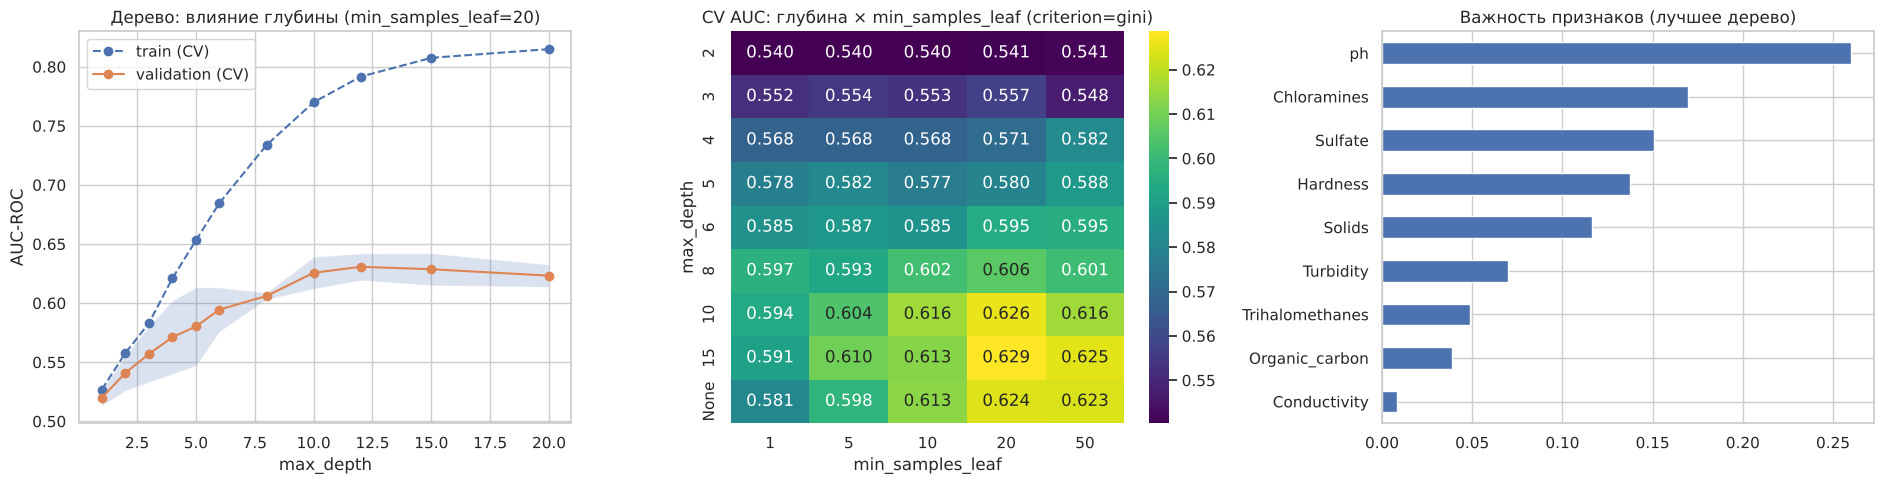

,лучший CV AUC,средний по сетке
param_clf__criterion,,
entropy,0.6196,0.5810
gini,0.6287,0.5853


In [14]:
gs = TUNED["Decision Tree"]
bp = {k: v for k, v in gs.best_params_.items()}
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20]
base = clone(dt_best).set_params(clf__max_depth=None)
tr, va = validation_curve(base, X_train, y_train, param_name="clf__max_depth", param_range=depths,
                          cv=cv, scoring="roc_auc", n_jobs=-1)
axes[0].plot(depths, tr.mean(1), "o--", label="train (CV)"); axes[0].plot(depths, va.mean(1), "o-", label="validation (CV)")
axes[0].fill_between(depths, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.2)
axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("AUC-ROC"); axes[0].legend()
axes[0].set_title(f"Дерево: влияние глубины (min_samples_leaf={bp['clf__min_samples_leaf']})")

r = pd.DataFrame(gs.cv_results_)
r = r[r["param_clf__criterion"] == bp["clf__criterion"]].copy()
r["depth"] = r["param_clf__max_depth"].apply(lambda v: "None" if v is None or pd.isna(v) else str(int(v)))
order = [str(d) for d in [2, 3, 4, 5, 6, 8, 10, 15]] + ["None"]
piv = r.pivot_table(index="depth", columns="param_clf__min_samples_leaf", values="mean_test_score", aggfunc="max").loc[order]
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=axes[1])
axes[1].set_title(f"CV AUC: глубина × min_samples_leaf (criterion={bp['clf__criterion']})")
axes[1].set_xlabel("min_samples_leaf"); axes[1].set_ylabel("max_depth")

imp = pd.Series(dt_best.named_steps["clf"].feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(ax=axes[2], color="#4C72B0"); axes[2].set_title("Важность признаков (лучшее дерево)")
plt.tight_layout(); plt.show()

crit = pd.DataFrame(gs.cv_results_).groupby("param_clf__criterion")["mean_test_score"].agg(["max", "mean"]).rename(columns={"max": "лучший CV AUC", "mean": "средний по сетке"})
crit

**Пояснение к блоку кода.** Три графика: (слева) влияние глубины дерева на AUC-ROC для обучающих и валидационных блоков (полоса — стандартное отклонение по блокам кросс-валидации); (в центре) тепловая карта CV AUC для сочетаний «глубина × минимальный размер листа» при лучшем критерии; (справа) важность признаков лучшего дерева. Ниже — сравнение критериев Джини и энтропии.

**Вывод по графикам.** *Слева:* качество на обучающих блоках монотонно растёт с глубиной (до 0.82), а на валидационных растёт лишь до глубины ≈ 10–12 (0.63) и затем стагнирует — типичная картина переобучения: при глубине ≥ 10 дерево подгоняется под обучающие данные. *В центре:* мелкие деревья (глубина 2–3) дают AUC лишь 0.54–0.56; ограничение листа `min_samples_leaf` 20–50 улучшает результат при большой глубине, так как сглаживает дерево (оптимум — глубина 15 при листе 20 — 0.629). *Справа:* больше всего вносят `ph`, `Chloramines`, `Sulfate` и `Hardness`; `Conductivity` почти не используется. *Таблица:* Джини (0.629) немного лучше энтропии (0.620), разница мала.

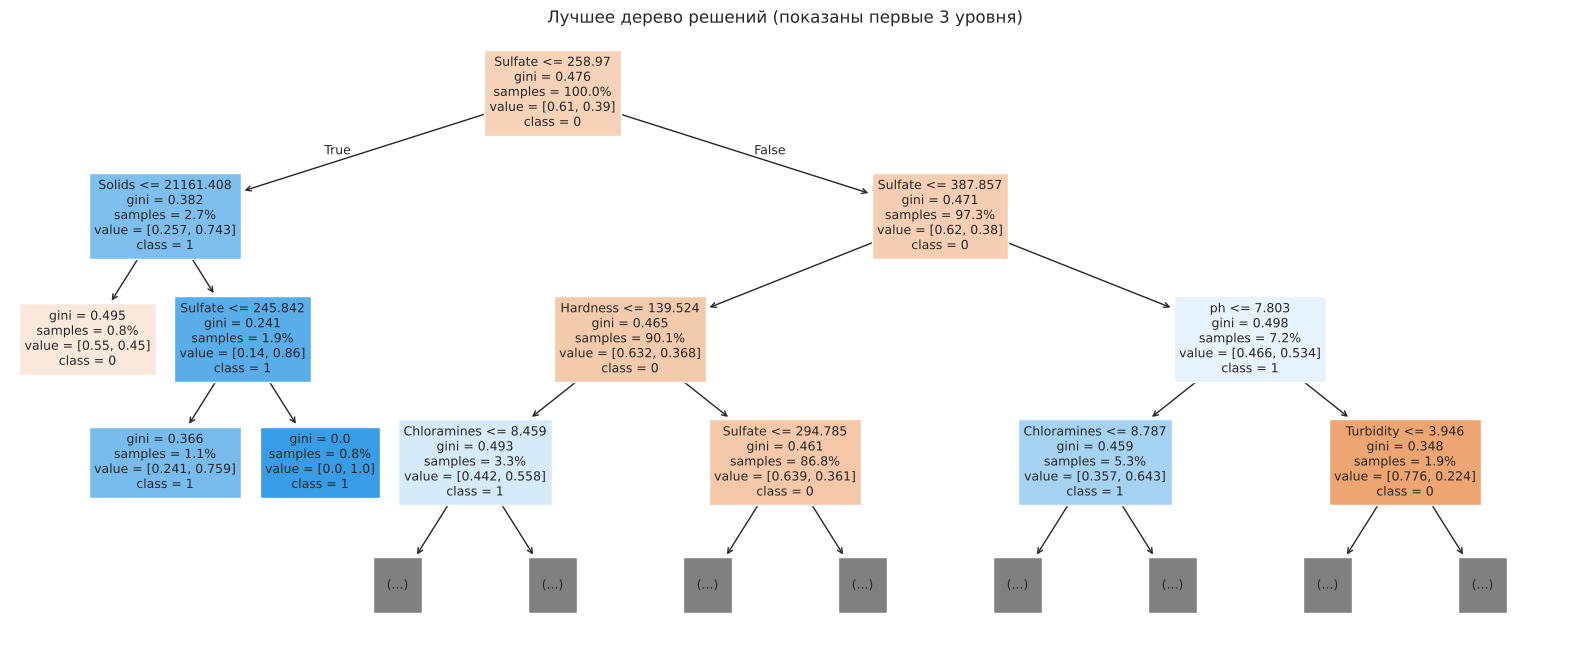

In [15]:
plt.figure(figsize=(20, 8))
plot_tree(dt_best.named_steps["clf"], feature_names=FEATURES, class_names=["0", "1"], filled=True, max_depth=3, fontsize=9, proportion=True)
plt.title("Лучшее дерево решений (показаны первые 3 уровня)")
plt.show()

**Пояснение к блоку кода.** Визуализация первых трёх уровней лучшего дерева (`plot_tree`): в каждом узле указаны условие разбиения, значение критерия Джини, доля образцов, распределение классов `value = [доля класса 0, доля класса 1]` и преобладающий класс.

**Вывод по рисунку.** Корень дерева — разбиение по `Sulfate ≤ 258.97`: в левую ветвь попадают лишь 2.7% образцов, но среди них **74% — пригодная вода** (класс 1), а в основной ветви (97.3%) доля класса 1 — 38%. Дальнейшие разбиения также используют `Solids`, `Hardness`, `ph`, `Chloramines`, `Turbidity`. Это показывает, что закономерности **нелинейны и локальны**: класс 1 чаще встречается при экстремальных значениях отдельных признаков (например, очень низких сульфатах), а не изменяется монотонно. Именно поэтому линейные методы здесь бесполезны, а нелинейные (дерево, kNN, SVM с RBF-ядром) дают лучший результат.

### 4.3. Линейный дискриминантный анализ

In [16]:
tune("LDA",
     make_pipe(LinearDiscriminantAnalysis(), "standard"),
     [{"clf__solver": ["svd"]},
      {"clf__solver": ["lsqr", "eigen"], "clf__shrinkage": [None, "auto", 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]}])
lda_best = TUNED["LDA"].best_estimator_

LDA: лучший CV AUC = 0.4776  (19 комбинаций, 1.4 с)
   лучшие параметры: {'solver': 'svd'}


**Пояснение к блоку кода.** Подбор гиперпараметров LDA: решатель `svd` (без параметров), а также `lsqr` и `eigen` с различными значениями сжатия (`shrinkage`) ковариационной матрицы — от отсутствия сжатия до полного (1.0), плюс автоматический выбор `auto`. Признаки стандартизуются.

**Вывод.** Лучшая конфигурация — `svd`, но CV AUC = **0.478**, то есть **ниже 0.5**: модель не находит линейно разделяющего направления, а небольшое отклонение от 0.5 вниз — результат случайных колебаний оценок при отсутствии сигнала.

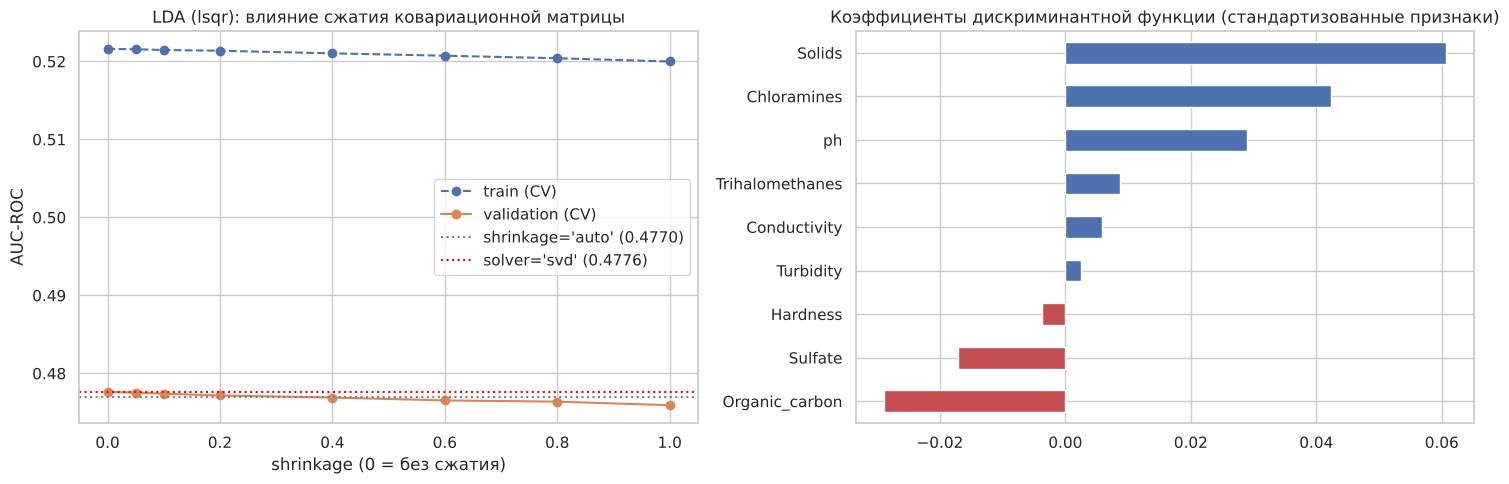

,param_clf__solver,param_clf__shrinkage,mean_train_score,mean_test_score
0,svd,NaN,0.5216,0.4776
1,lsqr,None,0.5216,0.4776
2,eigen,None,0.5216,0.4776
6,eigen,0.0500,0.5216,0.4775
5,lsqr,0.0500,0.5216,0.4775
8,eigen,0.1000,0.5215,0.4774


In [17]:
r = pd.DataFrame(TUNED["LDA"].cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
g = r[(r["param_clf__solver"] == "lsqr")].copy()
num = g[g["param_clf__shrinkage"].apply(lambda v: isinstance(v, float) or v is None)].copy()
num["sh"] = num["param_clf__shrinkage"].apply(lambda v: 0.0 if v is None else v)
num = num.sort_values("sh")
axes[0].plot(num["sh"], num["mean_train_score"], "o--", label="train (CV)")
axes[0].plot(num["sh"], num["mean_test_score"], "o-", label="validation (CV)")
auto = g[g["param_clf__shrinkage"] == "auto"]["mean_test_score"].iloc[0]
axes[0].axhline(auto, color="gray", ls=":", label=f"shrinkage='auto' ({auto:.4f})")
svd = r[r["param_clf__solver"] == "svd"]["mean_test_score"].iloc[0]
axes[0].axhline(svd, color="red", ls=":", label=f"solver='svd' ({svd:.4f})")
axes[0].set_xlabel("shrinkage (0 = без сжатия)"); axes[0].set_ylabel("AUC-ROC"); axes[0].legend()
axes[0].set_title("LDA (lsqr): влияние сжатия ковариационной матрицы")

coef = pd.Series(lda_best.named_steps["clf"].coef_[0], index=FEATURES).sort_values()
coef.plot.barh(ax=axes[1], color=["#C44E52" if v < 0 else "#4C72B0" for v in coef.values])
axes[1].set_title("Коэффициенты дискриминантной функции (стандартизованные признаки)")
plt.tight_layout(); plt.show()

r[["param_clf__solver", "param_clf__shrinkage", "mean_train_score", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(6)

**Пояснение к блоку кода.** Слева — влияние сжатия ковариационной матрицы на AUC-ROC (решатель `lsqr`) для обучающих и валидационных блоков, горизонтальные линии — `shrinkage='auto'` и решатель `svd`. Справа — коэффициенты линейной дискриминантной функции для стандартизованных признаков (их знак и величина показывают вклад признака). В таблице — топ-6 конфигураций.

**Вывод по графикам.** *Слева:* при любом `shrinkage` валидационный AUC равен 0.476–0.478, а обучающий — 0.520–0.522: параметр сжатия на качество практически не влияет (при 1.0 качество чуть хуже), и во всех случаях значения около 0.5 — LDA не лучше случайного угадывания. *Справа:* коэффициенты очень малы по модулю (максимум 0.06 у `Solids`), то есть линейная дискриминантная функция практически не разделяет классы. Вывод: данные не удовлетворяют допущениям LDA (нормальные распределения с разными средними и общей ковариацией) — средние значения признаков в классах одинаковы.

### 4.4. Метод опорных векторов

In [18]:
svm_specs = {
    "linear":  {"clf__C": [0.01, 0.1, 1, 10]},
    "rbf":     {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.001, 0.01, 0.1, 1.0]},
    "poly":    {"clf__C": [0.1, 1, 10], "clf__degree": [2, 3, 4], "clf__gamma": ["scale"]},
    "sigmoid": {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]},
}
for kern, grid in svm_specs.items():
    tune(f"SVM-{kern}", make_pipe(SVC(kernel=kern, random_state=SEED), "standard"), grid)

best_kernel = max(svm_specs, key=lambda k: TUNED[f"SVM-{k}"].best_score_)
TUNED["SVM"] = TUNED[f"SVM-{best_kernel}"]
print("\nЛучшее ядро:", best_kernel)
pd.DataFrame({k: {"лучший CV AUC": TUNED[f"SVM-{k}"].best_score_,
                  "параметры": {p.replace('clf__', ''): v for p, v in TUNED[f"SVM-{k}"].best_params_.items()}} for k in svm_specs}).T

SVM-linear: лучший CV AUC = 0.5291  (4 комбинаций, 3.7 с)
   лучшие параметры: {'C': 0.1}


SVM-rbf: лучший CV AUC = 0.7042  (20 комбинаций, 28.2 с)
   лучшие параметры: {'C': 10, 'gamma': 0.1}


SVM-poly: лучший CV AUC = 0.6903  (9 комбинаций, 11.5 с)
   лучшие параметры: {'C': 1, 'degree': 4, 'gamma': 'scale'}


SVM-sigmoid: лучший CV AUC = 0.4750  (9 комбинаций, 10.5 с)
   лучшие параметры: {'C': 10, 'gamma': 'scale'}

Лучшее ядро: rbf


,лучший CV AUC,параметры
linear,0.5291,{'C': 0.1}
rbf,0.7042,"{'C': 10, 'gamma': 0.1}"
poly,0.6903,"{'C': 1, 'degree': 4, 'gamma': 'scale'}"
sigmoid,0.4750,"{'C': 10, 'gamma': 'scale'}"


**Пояснение к блоку кода.** Для SVM каждое ядро (`linear`, `rbf`, `poly`, `sigmoid`) настраивается отдельной сеткой гиперпараметров: `C` для всех, `gamma` для RBF и sigmoid, степень `degree` для полиномиального. Признаки стандартизованы. Затем выбирается ядро с лучшим CV AUC, и оно считается итоговым «SVM».

**Вывод.** Результаты резко различаются в зависимости от ядра: **RBF — 0.704** (`C=10`, `gamma=0.1`), полиномиальное — 0.690 (степень 4), линейное — 0.529, сигмоидное — 0.475. То есть нелинейные ядра работают заметно лучше линейного: классы линейно неразделимы, но имеют локальную нелинейную структуру. Лучшее ядро — RBF.

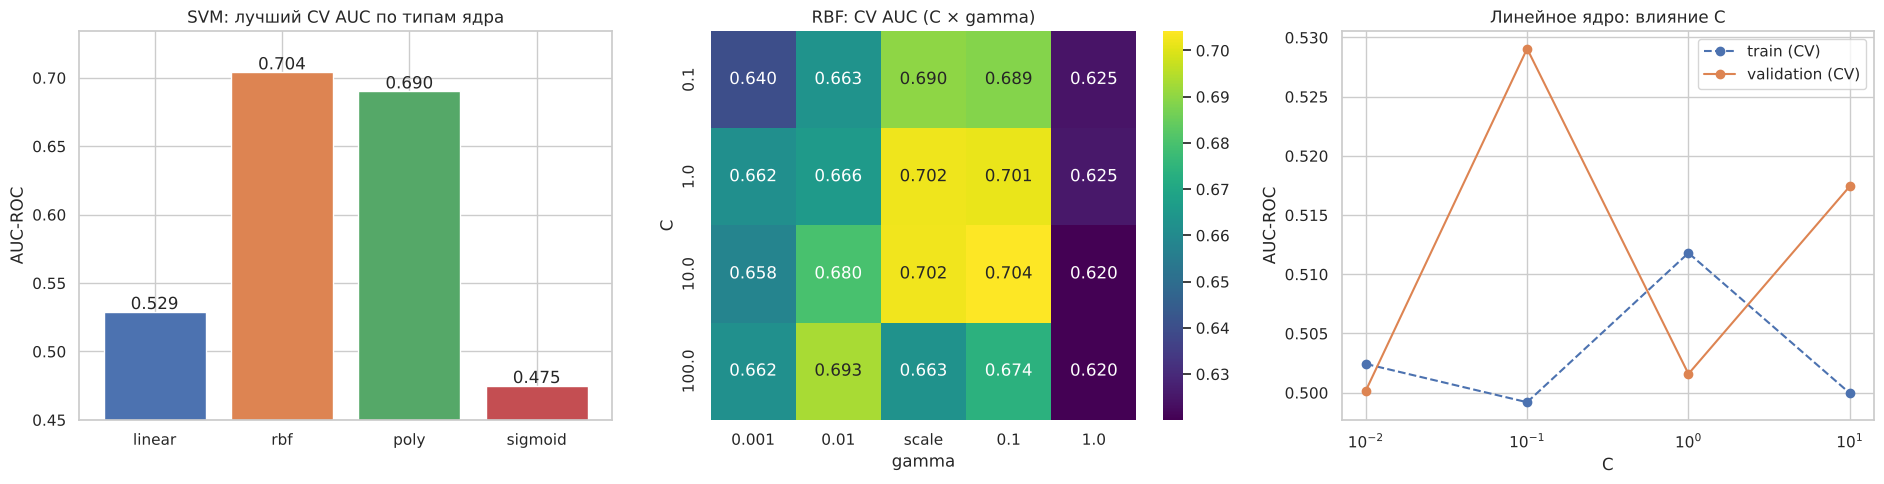

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
ks = list(svm_specs)
axes[0].bar(ks, [TUNED[f"SVM-{k}"].best_score_ for k in ks], color=sns.color_palette("deep", 4))
for i, k in enumerate(ks):
    axes[0].text(i, TUNED[f"SVM-{k}"].best_score_ + 0.002, f"{TUNED[f'SVM-{k}'].best_score_:.3f}", ha="center")
axes[0].set_ylim(0.45, max(TUNED[f"SVM-{k}"].best_score_ for k in ks) + 0.03)
axes[0].set_title("SVM: лучший CV AUC по типам ядра"); axes[0].set_ylabel("AUC-ROC")

r = pd.DataFrame(TUNED["SVM-rbf"].cv_results_)
r["gamma"] = r["param_clf__gamma"].astype(str)
piv = r.pivot_table(index="param_clf__C", columns="gamma", values="mean_test_score")
piv = piv[["0.001", "0.01", "scale", "0.1", "1.0"]]
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=axes[1])
axes[1].set_title("RBF: CV AUC (C × gamma)"); axes[1].set_xlabel("gamma"); axes[1].set_ylabel("C")

r = pd.DataFrame(TUNED["SVM-linear"].cv_results_)
axes[2].semilogx(r["param_clf__C"].astype(float), r["mean_train_score"], "o--", label="train (CV)")
axes[2].semilogx(r["param_clf__C"].astype(float), r["mean_test_score"], "o-", label="validation (CV)")
axes[2].set_title("Линейное ядро: влияние C"); axes[2].set_xlabel("C"); axes[2].set_ylabel("AUC-ROC"); axes[2].legend()
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Слева — лучший CV AUC для каждого типа ядра. В центре — тепловая карта CV AUC для RBF-ядра по сочетаниям параметров `C` и `gamma`. Справа — влияние `C` на AUC для линейного ядра (обучающие и валидационные блоки).

**Вывод по графикам.** *Слева:* RBF (0.704) и полиномиальное ядро (0.690) намного лучше линейного (0.529) и сигмоидного (0.475). *В центре:* качество чувствительно к `gamma`: при слишком большом `gamma = 1` ядро «узкое» и модель запоминает обучающие точки (AUC падает до 0.62, независимо от `C`), при очень малом `gamma = 0.001` граница почти линейная (0.64–0.66); оптимум — `gamma` ≈ 0.1 (или `scale` ≈ 0.11) и `C` = 1–10 (0.70). Слишком большое `C = 100` снижает качество из-за переобучения. *Справа:* для линейного ядра AUC колеблется около 0.50–0.53 при любом `C` — подбор `C` его не спасает.

### 4.5. Метод ближайших соседей

In [20]:
ks_grid = list(range(1, 80, 2))
_ = tune("kNN",
     make_pipe(KNeighborsClassifier(), "standard"),
     {"clf__n_neighbors": ks_grid, "clf__weights": ["uniform", "distance"],
      "clf__metric": ["euclidean", "manhattan", "chebyshev"]})

kNN: лучший CV AUC = 0.6711  (240 комбинаций, 107.4 с)
   лучшие параметры: {'metric': 'euclidean', 'n_neighbors': 35, 'weights': 'distance'}


**Пояснение к блоку кода.** Подбор гиперпараметров kNN: число соседей `k` (нечётные значения от 1 до 79), способ взвешивания (`uniform` — равные голоса, `distance` — вес обратно пропорционален расстоянию) и метрика расстояния (евклидова, манхэттенская, Чебышёва) — 240 комбинаций с кросс-валидацией. Признаки стандартизованы.

**Вывод.** Лучшая конфигурация: `k = 35`, веса `distance`, евклидова метрика; CV AUC = **0.671**.

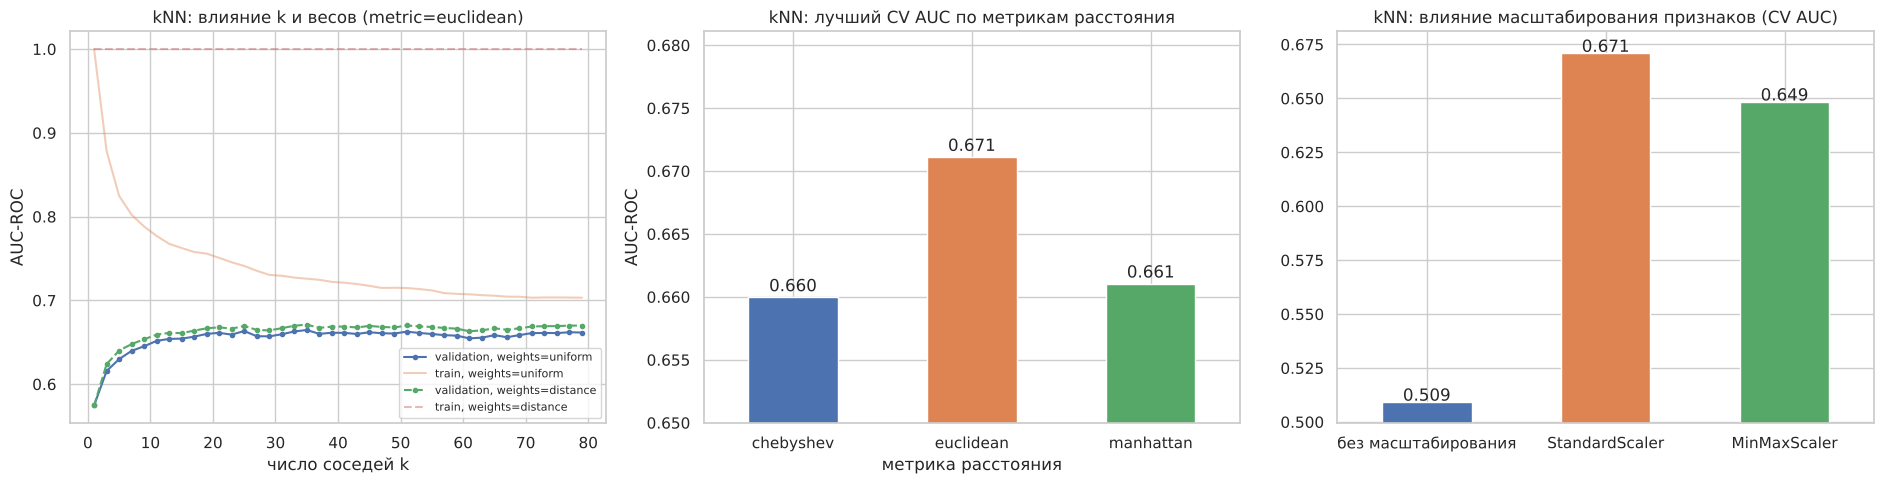

,CV AUC
без масштабирования,0.5094
StandardScaler,0.6711
MinMaxScaler,0.6485


In [21]:
gs = TUNED["kNN"]
bp = gs.best_params_
r = pd.DataFrame(gs.cv_results_)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for w, ls in [("uniform", "-"), ("distance", "--")]:
    g = r[(r["param_clf__weights"] == w) & (r["param_clf__metric"] == bp["clf__metric"])].sort_values("param_clf__n_neighbors")
    axes[0].plot(g["param_clf__n_neighbors"], g["mean_test_score"], ls, marker="o", ms=3, label=f"validation, weights={w}")
    axes[0].plot(g["param_clf__n_neighbors"], g["mean_train_score"], ls, alpha=.4, label=f"train, weights={w}")
axes[0].set_xlabel("число соседей k"); axes[0].set_ylabel("AUC-ROC"); axes[0].legend(fontsize=8)
axes[0].set_title(f"kNN: влияние k и весов (metric={bp['clf__metric']})")

m = r[r["param_clf__weights"] == bp["clf__weights"]].groupby(["param_clf__metric"])["mean_test_score"].max()
m.plot.bar(ax=axes[1], color=sns.color_palette("deep", 3), rot=0); axes[1].set_ylim(m.min() - 0.01, m.max() + 0.01)
axes[1].set_title("kNN: лучший CV AUC по метрикам расстояния"); axes[1].set_ylabel("AUC-ROC"); axes[1].set_xlabel("метрика расстояния")
for i, v in enumerate(m.values): axes[1].text(i, v + 0.0005, f"{v:.3f}", ha="center")

sc = {}
for label, scaler in [("без масштабирования", None), ("StandardScaler", "standard"), ("MinMaxScaler", "minmax")]:
    p = make_pipe(KNeighborsClassifier(n_neighbors=bp["clf__n_neighbors"], weights=bp["clf__weights"], metric=bp["clf__metric"]), scaler)
    sc[label] = cross_val_score(p, X_train, y_train, cv=cv, scoring="roc_auc").mean()
pd.Series(sc).plot.bar(ax=axes[2], color=sns.color_palette("deep", 3), rot=0)
axes[2].set_ylim(min(sc.values()) - 0.01, max(sc.values()) + 0.01); axes[2].set_title("kNN: влияние масштабирования признаков (CV AUC)")
for i, v in enumerate(sc.values()): axes[2].text(i, v + 0.0005, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()
pd.Series(sc, name="CV AUC").to_frame()

**Пояснение к блоку кода.** Три графика: (слева) зависимость AUC-ROC от числа соседей `k` для двух способов взвешивания (обучающие и валидационные блоки); (в центре) лучший AUC для трёх метрик расстояния; (справа) эффект масштабирования — тот же kNN без масштабирования, со `StandardScaler` и `MinMaxScaler`. Ниже — таблица значений.

**Вывод по графикам.** *Слева:* при `k = 1` AUC на валидации всего 0.58 (при том что на обучающей выборке 1.0 — модель запоминает данные); с ростом `k` качество растёт и выходит на плато около 0.66–0.67 при `k` ≈ 25–50; дальше почти не меняется. Взвешивание по расстоянию (`distance`) стабильно немного лучше равных весов. Обучающий AUC при `distance` остаётся равным 1.0 (каждая точка — свой ближайший сосед), а при `uniform` снижается с ростом `k`, приближаясь к валидационному. *В центре:* евклидова метрика (0.671) лучше манхэттенской (0.661) и Чебышёва (0.660); различия небольшие. *Справа:* масштабирование критично: **без него AUC = 0.509** (практически случайно — расстояние определяется признаком `Solids` с масштабом десятки тысяч), со стандартизацией — **0.671**, с нормализацией в [0, 1] — 0.649.

### 4.6. Дополнительно: влияние весов классов и априорных вероятностей

Классы несбалансированы (61% / 39%), поэтому классификаторы по умолчанию стремятся предсказывать преобладающий класс, что снижает Recall для пригодной воды. Здесь исследуется, как меняются метрики, если задать равные веса классов (`class_weight="balanced"` для дерева и SVM) или равные априорные вероятности (`priors` для LDA и GaussianNB). Метрики считаются по кросс-валидации на обучающей выборке (тест не используется).

In [22]:
def cv_metrics(est):
    res = cross_validate(est, X_train, y_train, cv=cv, n_jobs=-1,
                         scoring={"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1": "f1", "AUC-ROC": "roc_auc"})
    return {k: res[f"test_{k}"].mean() for k in ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]}

rows = {}
for name, key, par, variants in [
        ("Decision Tree", "Decision Tree", "clf__class_weight", {"без весов": None, "balanced": "balanced"}),
        ("SVM", "SVM", "clf__class_weight", {"без весов": None, "balanced": "balanced"}),
        ("LDA", "LDA", "clf__priors", {"по данным": None, "равные [0.5, 0.5]": [0.5, 0.5]}),
        ("GaussianNB", "GaussianNB", "clf__priors", {"по данным": None, "равные [0.5, 0.5]": [0.5, 0.5]})]:
    for label, val in variants.items():
        est = clone(TUNED[key].best_estimator_).set_params(**{par: val})
        rows[(name, label)] = cv_metrics(est)
cw = pd.DataFrame(rows).T
cw.index.names = ["Метод", "Веса / априорные вероятности классов"]
cw

Accuracy  Precision  Recall     F1  AUC-ROC
Метод         Веса / априорные вероятности классов                                             
Decision Tree без весов                               0.6195     0.5157  0.4051 0.4532   0.6287
              balanced                                0.5958     0.4843  0.5529 0.5158   0.6302
SVM           без весов                               0.6756     0.6241  0.4227 0.5035   0.7042
              balanced                                0.6546     0.5546  0.5822 0.5675   0.6973
LDA           по данным                               0.6099     0.0000  0.0000 0.0000   0.4776
              равные [0.5, 0.5]                       0.4966     0.3796  0.4619 0.4164   0.4776
GaussianNB    по данным                               0.6275     0.5519  0.2446 0.3379   0.5867
              равные [0.5, 0.5]                       0.5950     0.4797  0.4256 0.4505   0.5867

**Пояснение к блоку кода.** Для лучших моделей решающих деревьев, SVM, LDA и GaussianNB сравниваются два варианта: веса классов по умолчанию и сбалансированные (`class_weight="balanced"` для дерева и SVM) либо равные априорные вероятности (`priors=[0.5, 0.5]` для LDA и GaussianNB). Считаются все пять метрик по кросс-валидации на обучающей выборке.

**Вывод.** Балансировка меняет компромисс между Precision и Recall, но не улучшает ранжирующую способность (AUC почти не меняется). Для SVM Recall вырастает с 0.42 до 0.58, а Precision падает с 0.62 до 0.55, F1 растёт с 0.50 до 0.57, но Accuracy падает с 0.676 до 0.655. Для дерева Recall 0.41 → 0.55, F1 0.45 → 0.52. У LDA без балансировки метод вообще не предсказывает класс 1 (Precision = Recall = 0), с равными априорными вероятностями Recall 0.46 при Accuracy 0.497. У GaussianNB Recall растёт с 0.24 до 0.43. Вывод: при необходимости найти больше пригодных образцов (высокий Recall) достаточно сместить порог или веса, но за это придётся платить точностью.

## 5. Нейронная сеть на TensorFlow

### 5.1. Архитектура и условия экспериментов

**Тип сети** — многослойный перцептрон (полносвязная сеть прямого распространения), реализованный в `tf.keras.Sequential`. Данные — табличные (9 признаков), поэтому свёрточные и рекуррентные слои не нужны.

**Базовая архитектура:**

| Слой | Параметры | Назначение |
|---|---|---|
| `Input` | 9 признаков | стандартизованные показатели воды |
| `Dense(64)` + `ReLU` | 640 параметров | первое скрытое представление |
| `Dropout(0.3)` | — | регуляризация: случайно «выключает» 30% нейронов при обучении |
| `Dense(32)` + `ReLU` | 2 080 параметров | второе скрытое представление |
| `Dropout(0.3)` | — | регуляризация |
| `Dense(1)` + `Sigmoid` | 33 параметра | выход — вероятность класса 1 («пригодна») |

**Функция активации** скрытых слоёв — ReLU (быстро обучается, не «насыщается» при положительных значениях); на выходе — сигмоида, сжимающая значение в диапазон (0, 1), что соответствует вероятности. **Функция потерь** — бинарная перекрёстная энтропия (`binary_crossentropy`), стандартная для бинарной классификации. **Оптимизатор** — Adam со скоростью обучения 0.001 (адаптивный градиентный метод). Мониторятся Accuracy и AUC-ROC.

**Данные.** Признаки заполняются медианой и стандартизуются (по обучающей выборке). Из обучающей выборки выделяется валидационная часть 20% (524 образца, стратифицированно): по ней отслеживаются `val_loss`, `val_accuracy`, `val_auc` и по ней выбираются гиперпараметры; **тестовая выборка в экспериментах с сетью не используется** до самого конца.

**Ранняя остановка.** В экспериментах используется `EarlyStopping` (остановка, если `val_loss` не улучшается 15 эпох, с возвратом весов лучшей эпохи): это защита от переобучения и способ автоматически выбрать число эпох. Только в первом эксперименте сеть намеренно обучается 200 эпох без ранней остановки, чтобы показать переобучение.

**Мониторинг в TensorBoard.** Каждый запуск пишет журнал в папку `logs/<эксперимент>/<вариант>` через колбэк `keras.callbacks.TensorBoard`; просмотр: `tensorboard --logdir logs` (см. конец раздела 5).

**Эксперименты:** (1) число эпох; (2) размер батча; (3) число слоёв и нейронов; (4) функции активации; (5) оптимизатор и скорость обучения; (6) регуляризация. В каждом изменяется один фактор при остальных базовых; один запуск на вариант (зерно фиксировано), поэтому различия в пределах ± 0.01–0.02 по AUC находятся в зоне случайных колебаний — оценка устойчивости приведена в разделе 6.

In [23]:
prep = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]).fit(X_train)
Xs_train, Xs_test = prep.transform(X_train), prep.transform(X_test)
X_tr, X_val, y_tr, y_val = train_test_split(Xs_train, y_train.values, test_size=0.2, stratify=y_train.values, random_state=SEED)

print("Нейросеть: обучение", X_tr.shape, "| валидация", X_val.shape, "| тест (не используется до конца)", Xs_test.shape)
print("Доля класса 1: train = {:.3f}, val = {:.3f}".format(y_tr.mean(), y_val.mean()))
print("Пропусков после заполнения:", np.isnan(Xs_train).sum() + np.isnan(Xs_test).sum(),
      "| среднее/СКО признаков в обучающей части:", X_tr.mean().round(2), X_tr.std().round(2))

Нейросеть: обучение (2096, 9) | валидация (524, 9) | тест (не используется до конца) (656, 9)
Доля класса 1: train = 0.390, val = 0.389
Пропусков после заполнения: 0 | среднее/СКО признаков в обучающей части: 0.0 1.0


**Пояснение к блоку кода.** Подготовка данных для нейросети: пропуски заполняются медианой, признаки стандартизуются (обучение преобразований — только на обучающей выборке), затем из обучающей выборки стратифицированно выделяется 20% на валидацию. Валидационная часть нужна, чтобы следить за переобучением и выбирать гиперпараметры, не трогая тест.

**Вывод.** Для обучения остаётся 2 096 образцов, для валидации — 524, тест (656) не используется. Доли класса 1 одинаковы (0.390 и 0.389), пропусков нет, среднее признаков 0 и СКО 1 — стандартизация выполнена.

In [24]:
LOG_ROOT = "logs"
shutil.rmtree(LOG_ROOT, ignore_errors=True)

def build_model(hidden=(64, 32), activation="relu", dropout=0.3, optimizer="adam", lr=1e-3, l2=0.0, seed=SEED):
    tf.keras.utils.set_random_seed(seed)
    model = keras.Sequential([keras.Input(shape=(X_tr.shape[1],))])
    for units in hidden:
        model.add(layers.Dense(units, activation=activation, kernel_regularizer=regularizers.l2(l2) if l2 else None))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    opt = {"adam": keras.optimizers.Adam(lr), "sgd": keras.optimizers.SGD(lr, momentum=0.9),
           "rmsprop": keras.optimizers.RMSprop(lr)}[optimizer]
    model.compile(optimizer=opt, loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

RUNS = {}       # название эксперимента -> (модель, история, результаты, конфигурация)

def train(run, epochs=100, batch_size=32, patience=15, early_stop=True, **cfg):
    model = build_model(**cfg)
    cbs = [keras.callbacks.TensorBoard(log_dir=f"{LOG_ROOT}/{run}")]
    if early_stop:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
    t0 = time.time()
    h = model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size, callbacks=cbs, verbose=0)
    hist = pd.DataFrame(h.history)
    b = int(hist["val_loss"].idxmin())
    rec = {"эксперимент": run, "эпох выполнено": len(hist), "лучшая эпоха": b + 1,
           "train loss": hist.loc[b, "loss"], "val loss": hist.loc[b, "val_loss"],
           "train acc": hist.loc[b, "accuracy"], "val acc": hist.loc[b, "val_accuracy"],
           "val AUC": hist.loc[b, "val_auc"], "время, с": time.time() - t0}
    RUNS[run] = (model, hist, rec, dict(batch_size=batch_size, **cfg))
    return model, hist, rec

model_demo = build_model()
model_demo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,753 (10.75 KB)

 Trainable params: 2,753 (10.75 KB)

 Non-trainable params: 0 (0.00 B)

**Пояснение к блоку кода.** Определяются функция `build_model` (строит сеть `Sequential` с заданным числом слоёв и нейронов, функцией активации, Dropout, L2-регуляризацией и оптимизатором; выход — один нейрон с сигмоидой; потери — бинарная перекрёстная энтропия; метрики — Accuracy и AUC) и функция `train` (обучает сеть, пишет журнал для TensorBoard в папку `logs/`, использует раннюю остановку, возвращает историю и сводку: лучшую эпоху и метрики на ней). Затем печатается структура базовой сети (`model.summary()`).

**Вывод.** Базовая сеть 64-32 имеет 2 753 обучаемых параметра: 640 в первом слое (9·64 + 64), 2 080 во втором (64·32 + 32) и 33 в выходном; слои Dropout параметров не имеют.

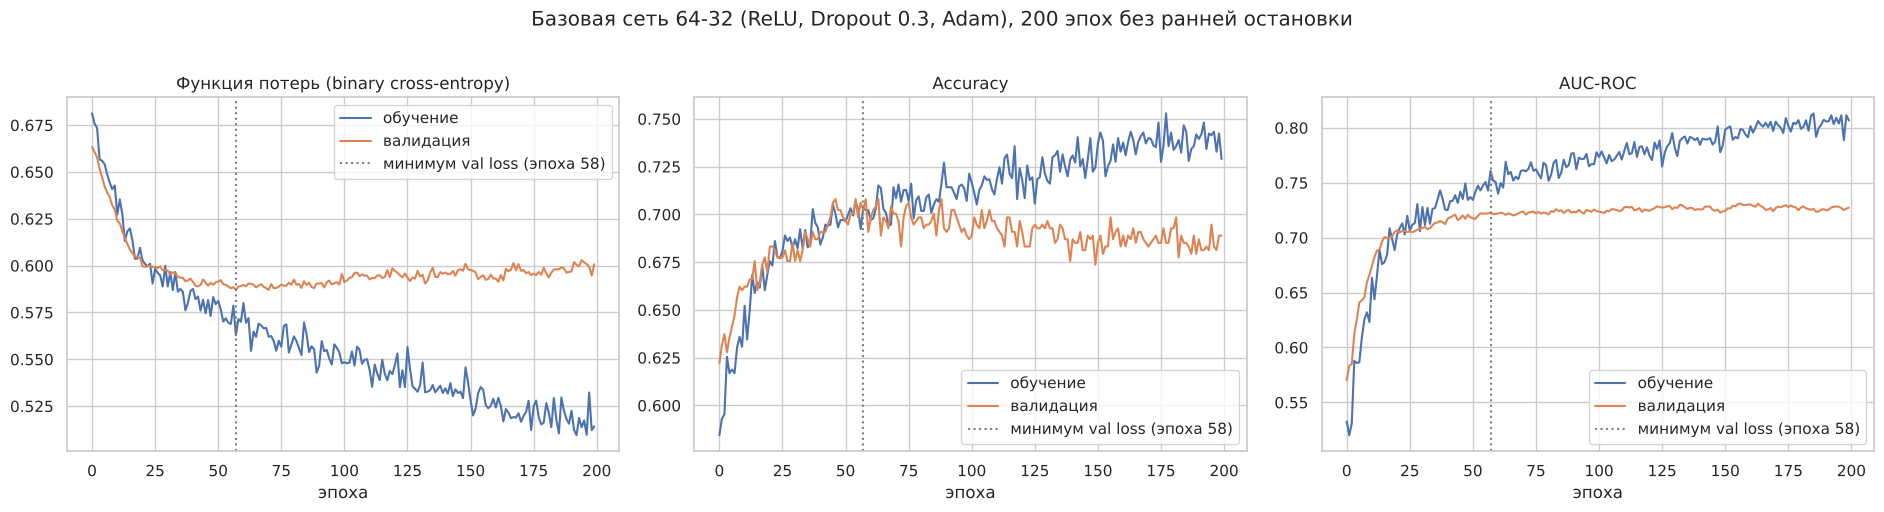

,loss,val_loss,accuracy,val_accuracy,auc,val_auc
эпоха,,,,,,
1,0.6812,0.6634,0.5844,0.6221,0.5327,0.5704
5,0.6560,0.6472,0.6169,0.6355,0.5859,0.6253
10,0.6428,0.6301,0.6307,0.6603,0.6233,0.6660
20,0.6095,0.6043,0.6684,0.6698,0.6886,0.7052
30,0.5999,0.5976,0.6823,0.6851,0.7058,0.7081
50,0.5794,0.5912,0.6970,0.6985,0.7369,0.7185
100,0.5479,0.5955,0.7214,0.6870,0.7778,0.7241
150,0.5377,0.5981,0.7247,0.6737,0.7837,0.7239
200,0.5142,0.6007,0.7290,0.6889,0.8067,0.7274


In [25]:
_, hist_long, rec_long = train("base_200_epochs", epochs=200, early_stop=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
best = rec_long["лучшая эпоха"] - 1
for ax, (tr_c, va_c, title) in zip(axes, [("loss", "val_loss", "Функция потерь (binary cross-entropy)"),
                                          ("accuracy", "val_accuracy", "Accuracy"), ("auc", "val_auc", "AUC-ROC")]):
    ax.plot(hist_long[tr_c], label="обучение"); ax.plot(hist_long[va_c], label="валидация")
    ax.axvline(best, color="gray", ls=":", label=f"минимум val loss (эпоха {best+1})")
    ax.set_xlabel("эпоха"); ax.set_title(title); ax.legend()
plt.suptitle("Базовая сеть 64-32 (ReLU, Dropout 0.3, Adam), 200 эпох без ранней остановки", y=1.02)
plt.tight_layout(); plt.show()

ep = [e for e in [1, 5, 10, 20, 30, 50, 100, 150, 200] if e <= len(hist_long)]
hist_long.loc[[e - 1 for e in ep], ["loss", "val_loss", "accuracy", "val_accuracy", "auc", "val_auc"]].set_index(pd.Index(ep, name="эпоха"))

**Пояснение к блоку кода.** **Эксперимент 1 — число эпох.** Базовая сеть обучается 200 эпох **без ранней остановки**; строятся кривые функции потерь, Accuracy и AUC для обучающей и валидационной выборок, штриховая линия — эпоха с минимальным `val_loss`. Таблица показывает метрики на выбранных эпохах.

**Вывод по графикам и таблице.** Функция потерь на обучении монотонно убывает (0.68 → 0.51), а на валидации достигает минимума около 58-й эпохи (0.591) и затем **растёт** (0.601 к 200-й эпохе) — классическое **переобучение**: сеть начинает запоминать обучающие данные. Accuracy и AUC на обучении продолжают расти (AUC 0.81 к 200-й эпохе), а на валидации выходят на плато: accuracy ≈ 0.70 на 50-й эпохе и затем снижается до 0.69, AUC ≈ 0.72–0.73. Слишком мало эпох (5–10) приводят к недообучению (val AUC 0.63–0.67). Оптимум — 50–60 эпох; дальнейшее обучение не даёт выигрыша. Поэтому в остальных экспериментах используется ранняя остановка по `val_loss`.

In [26]:
def experiment(title, configs, **common):
    rows, hists = [], {}
    for label, cfg in configs.items():
        kw = {**common, **cfg}
        _, h, rec = train(f"{title}/{label}", **kw)
        rec["вариант"] = label; rows.append(rec); hists[label] = h
    out = pd.DataFrame(rows).set_index("вариант").drop(columns="эксперимент")
    return out, hists

def plot_experiment(out, hists, title):
    fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
    for label, h in hists.items():
        axes[0].plot(h["val_loss"], label=label)
    axes[0].set_xlabel("эпоха"); axes[0].set_ylabel("val loss"); axes[0].set_title("Валидационная функция потерь"); axes[0].legend(fontsize=8)
    out["val AUC"].plot.bar(ax=axes[1], color=sns.color_palette("deep", len(out)), rot=30)
    axes[1].set_ylim(out["val AUC"].min() - 0.02, out["val AUC"].max() + 0.01); axes[1].set_title("val AUC (на лучшей эпохе)")
    out["val acc"].plot.bar(ax=axes[2], color=sns.color_palette("deep", len(out)), rot=30)
    axes[2].set_ylim(out["val acc"].min() - 0.02, out["val acc"].max() + 0.01); axes[2].set_title("val accuracy (на лучшей эпохе)")
    plt.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Вспомогательные функции для серии экспериментов: `experiment` запускает обучение для набора вариантов (изменяется один гиперпараметр, остальные базовые, ранняя остановка с терпением 15 эпох, максимум 100 эпох) и собирает таблицу результатов; `plot_experiment` строит три графика — кривые валидационной функции потерь по вариантам, столбцы val AUC и val Accuracy на лучшей эпохе. Вывода у блока нет.

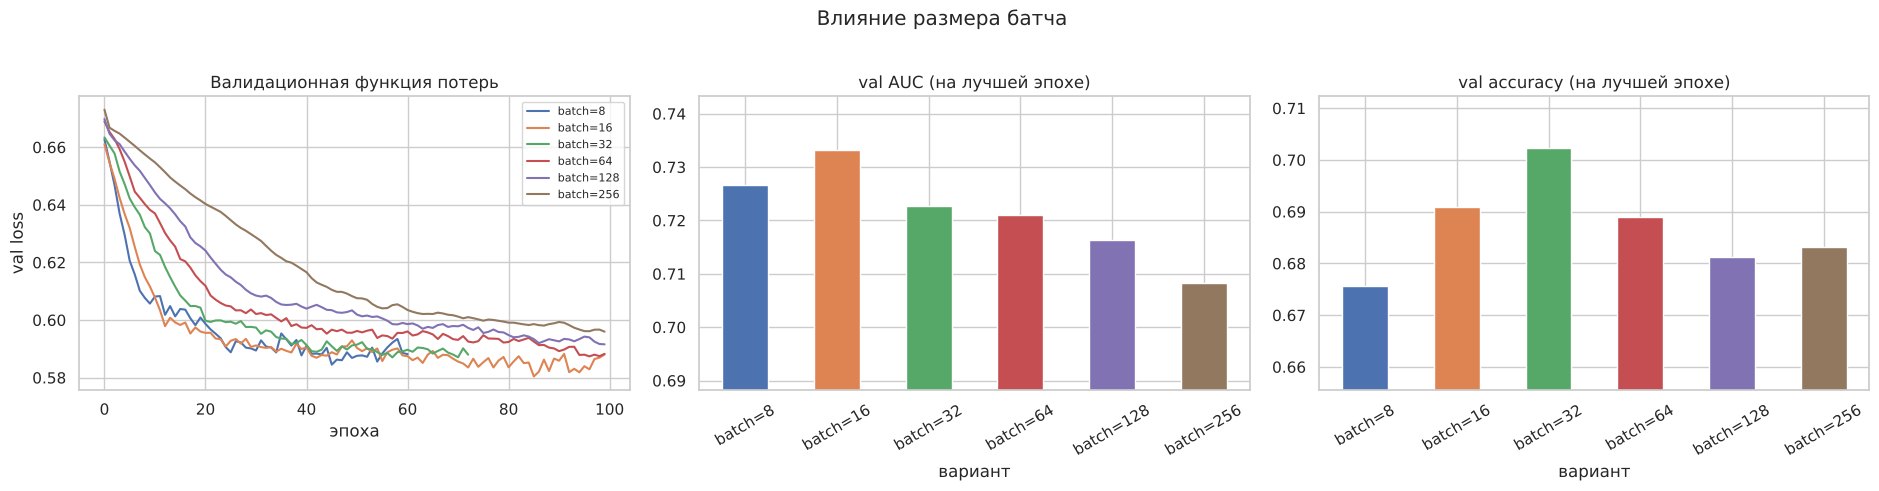

,эпох выполнено,лучшая эпоха,train loss,val loss,train acc,val acc,val AUC,"время, с"
вариант,,,,,,,,
batch=8,61,46,0.5728,0.5845,0.7032,0.6756,0.7266,74.5742
batch=16,100,86,0.5503,0.5804,0.7075,0.6908,0.7332,66.4057
batch=32,73,58,0.5628,0.5870,0.7032,0.7023,0.7227,33.2433
batch=64,100,97,0.5677,0.5874,0.7018,0.6889,0.7209,29.7796
batch=128,100,100,0.5659,0.5916,0.7061,0.6813,0.7163,25.0050
batch=256,100,100,0.5828,0.5960,0.7004,0.6832,0.7083,19.1744


In [27]:
exp_batch, h_batch = experiment("batch", {f"batch={b}": {"batch_size": b} for b in [8, 16, 32, 64, 128, 256]})
plot_experiment(exp_batch, h_batch, "Влияние размера батча")
exp_batch

**Пояснение к блоку кода.** **Эксперимент 2 — размер батча** (8, 16, 32, 64, 128, 256 образцов за один шаг градиентного спуска). Для каждого значения сеть обучается с ранней остановкой; сравниваются метрики на лучшей эпохе и время обучения.

**Вывод по графикам и таблице.** Малые батчи дают более «шумные» обновления и лучше обобщают: val AUC 0.727 (8), **0.733 (16)**, 0.723 (32), 0.721 (64), 0.716 (128), 0.708 (256); для больших батчей (64–256) число шагов за эпоху мало, и сеть не успевает обучиться за 100 эпох (лучшая эпоха 97–100, кривая потерь ещё не вышла на минимум). Зато время обучения растёт при уменьшении батча: 19 с (256) против 75 с (8). Компромисс — батч 16–64; разница между 8, 16 и 32 по AUC (0.01) сопоставима с шумом эксперимента.

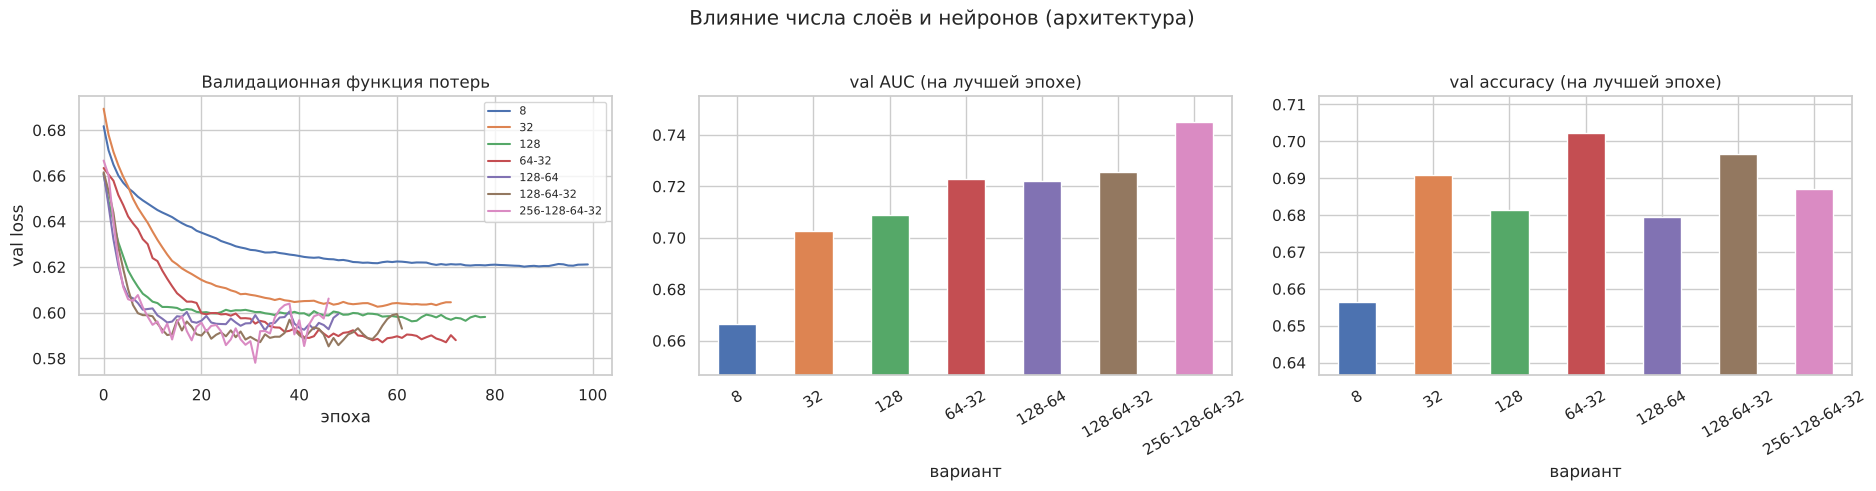

,эпох выполнено,лучшая эпоха,train loss,val loss,train acc,val acc,val AUC,"время, с"
вариант,,,,,,,,
8,100,87,0.6279,0.6202,0.6503,0.6565,0.6665,42.2894
32,72,57,0.5955,0.6026,0.6803,0.6908,0.7025,31.3937
128,79,64,0.5634,0.5962,0.7052,0.6813,0.7087,33.0884
64-32,73,58,0.5628,0.5870,0.7032,0.7023,0.7227,31.7144
128-64,49,34,0.5573,0.5923,0.7199,0.6794,0.7219,25.7639
128-64-32,62,47,0.5462,0.5853,0.7171,0.6966,0.7255,33.6072
256-128-64-32,47,32,0.5311,0.5781,0.7366,0.6870,0.7451,28.5826


In [28]:
exp_arch, h_arch = experiment("arch", {
    "8": {"hidden": (8,)}, "32": {"hidden": (32,)}, "128": {"hidden": (128,)},
    "64-32": {"hidden": (64, 32)}, "128-64": {"hidden": (128, 64)},
    "128-64-32": {"hidden": (128, 64, 32)}, "256-128-64-32": {"hidden": (256, 128, 64, 32)}})
plot_experiment(exp_arch, h_arch, "Влияние числа слоёв и нейронов (архитектура)")
exp_arch

**Пояснение к блоку кода.** **Эксперимент 3 — число слоёв и нейронов.** Сравниваются сети с одним скрытым слоем (8, 32, 128 нейронов) и с несколькими (64-32, 128-64, 128-64-32, 256-128-64-32), везде ReLU и Dropout 0.3.

**Вывод по графикам и таблице.** Слишком маленькая сеть (8 нейронов) недообучается: val AUC 0.667, val loss 0.620 — кривая потерь выходит на плато высоко. Увеличение ёмкости улучшает результат: 32 нейрона — 0.703, 128 — 0.709, 64-32 — 0.723, 128-64-32 — 0.726, **256-128-64-32 — 0.745** (лучший). Более глубокие сети быстрее достигают минимума потерь (на 32–47 эпохах против 57–87 у мелких) и затем сразу переобучаются, поэтому ранняя остановка принципиальна. Accuracy от архитектуры зависит слабо (0.68–0.70): лучшая по accuracy сеть 64-32 (0.702). Важно: val AUC выбранной сети (0.745) завышен, поскольку это максимум среди многих вариантов, оценённых на одной и той же валидационной выборке; оценка на тесте будет ниже.

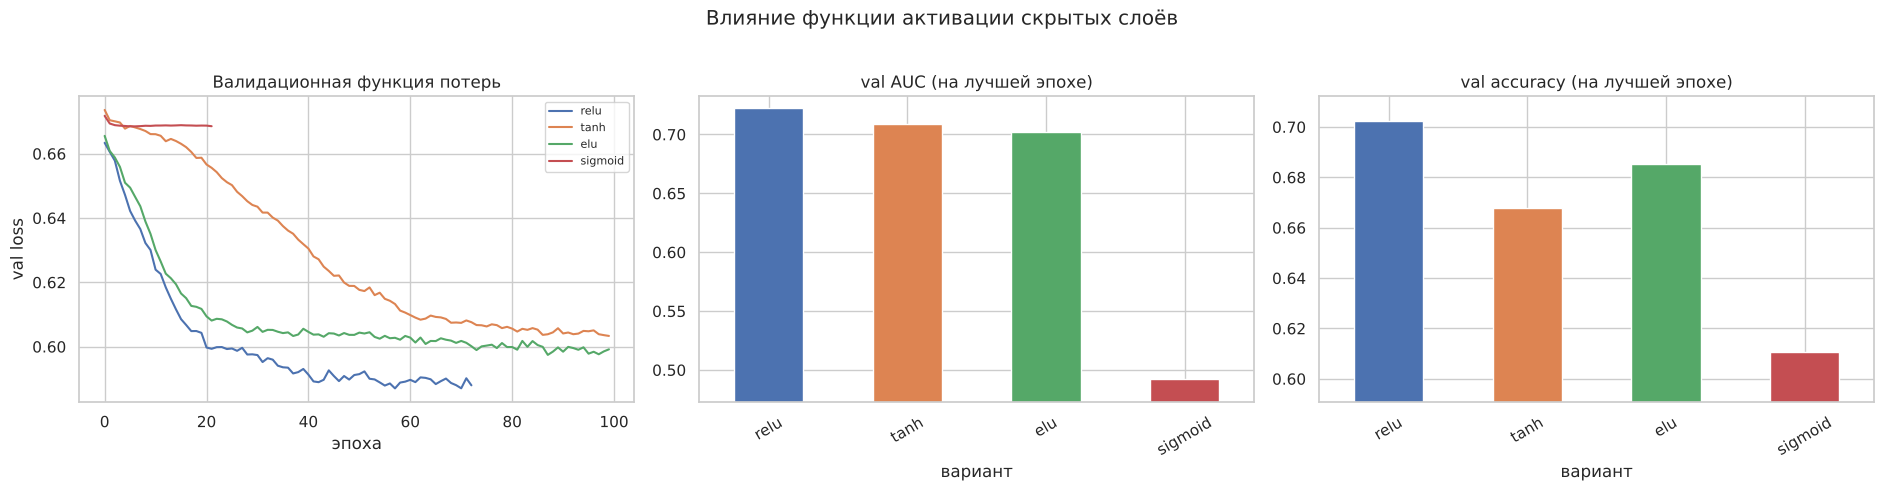

,эпох выполнено,лучшая эпоха,train loss,val loss,train acc,val acc,val AUC,"время, с"
вариант,,,,,,,,
relu,73,58,0.5628,0.5870,0.7032,0.7023,0.7227,34.3271
tanh,100,100,0.6011,0.6033,0.6751,0.6679,0.7089,46.2280
elu,100,88,0.6011,0.5974,0.6775,0.6851,0.7022,48.9925
sigmoid,22,7,0.6764,0.6685,0.5992,0.6107,0.4925,11.7539


In [29]:
exp_act, h_act = experiment("activation", {a: {"activation": a} for a in ["relu", "tanh", "elu", "sigmoid"]})
plot_experiment(exp_act, h_act, "Влияние функции активации скрытых слоёв")
exp_act

**Пояснение к блоку кода.** **Эксперимент 4 — функция активации** скрытых слоёв: ReLU, tanh, ELU, sigmoid.

**Вывод по графикам и таблице.** ReLU лучше всех (val AUC 0.723, val loss 0.587, остановка на 58-й эпохе); tanh (0.709) и ELU (0.702) учатся заметно медленнее — лучшая эпоха 100 и 88, то есть к ограничению в 100 эпох они ещё не завершили обучение. **Sigmoid в скрытых слоях не обучается вообще**: val AUC 0.4925 (уровень случайного угадывания), остановка на 22-й эпохе — типичная проблема затухающего градиента: производная сигмоиды не превышает 0.25, и градиенты при прохождении слоёв сильно ослабевают.

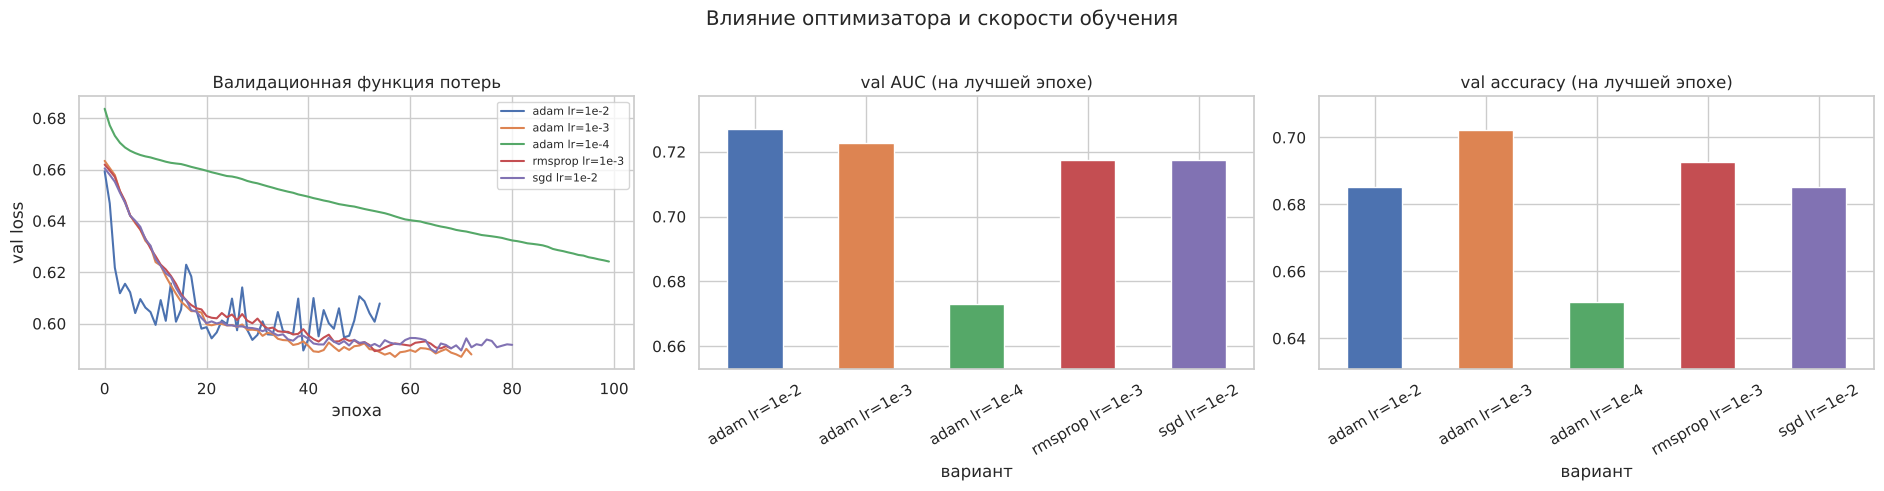

,эпох выполнено,лучшая эпоха,train loss,val loss,train acc,val acc,val AUC,"время, с"
вариант,,,,,,,,
adam lr=1e-2,55,40,0.5591,0.5895,0.7104,0.6851,0.7271,27.6855
adam lr=1e-3,73,58,0.5628,0.5870,0.7032,0.7023,0.7227,34.9468
adam lr=1e-4,100,100,0.6213,0.6242,0.6608,0.6508,0.6729,50.8208
rmsprop lr=1e-3,69,54,0.5762,0.5893,0.6994,0.6927,0.7175,33.7398
sgd lr=1e-2,81,66,0.5713,0.5889,0.6980,0.6851,0.7174,38.6615


In [30]:
exp_opt, h_opt = experiment("optimizer", {
    "adam lr=1e-2": {"optimizer": "adam", "lr": 1e-2}, "adam lr=1e-3": {"optimizer": "adam", "lr": 1e-3},
    "adam lr=1e-4": {"optimizer": "adam", "lr": 1e-4}, "rmsprop lr=1e-3": {"optimizer": "rmsprop", "lr": 1e-3},
    "sgd lr=1e-2": {"optimizer": "sgd", "lr": 1e-2}})
plot_experiment(exp_opt, h_opt, "Влияние оптимизатора и скорости обучения")
exp_opt

**Пояснение к блоку кода.** **Эксперимент 5 — оптимизатор и скорость обучения:** Adam (lr 0.01, 0.001, 0.0001), RMSprop (0.001), SGD с моментом 0.9 (0.01).

**Вывод по графикам и таблице.** Adam с lr = 0.01 и 0.001 дают близкий результат (val AUC 0.727 и 0.723): при большем шаге сеть быстрее достигает минимума (40-я эпоха против 58-й), но кривая потерь более шумная. При lr = 0.0001 шаг слишком мал: за 100 эпох сеть не обучается до конца (лучшая эпоха = 100, val AUC 0.673). RMSprop (0.718) и SGD с моментом (0.717) работают немного хуже Adam, но сопоставимо. Разброс val AUC между «нормальными» вариантами — около 0.01, то есть при данном объёме данных выбор оптимизатора не критичен, критичен только разумный шаг.

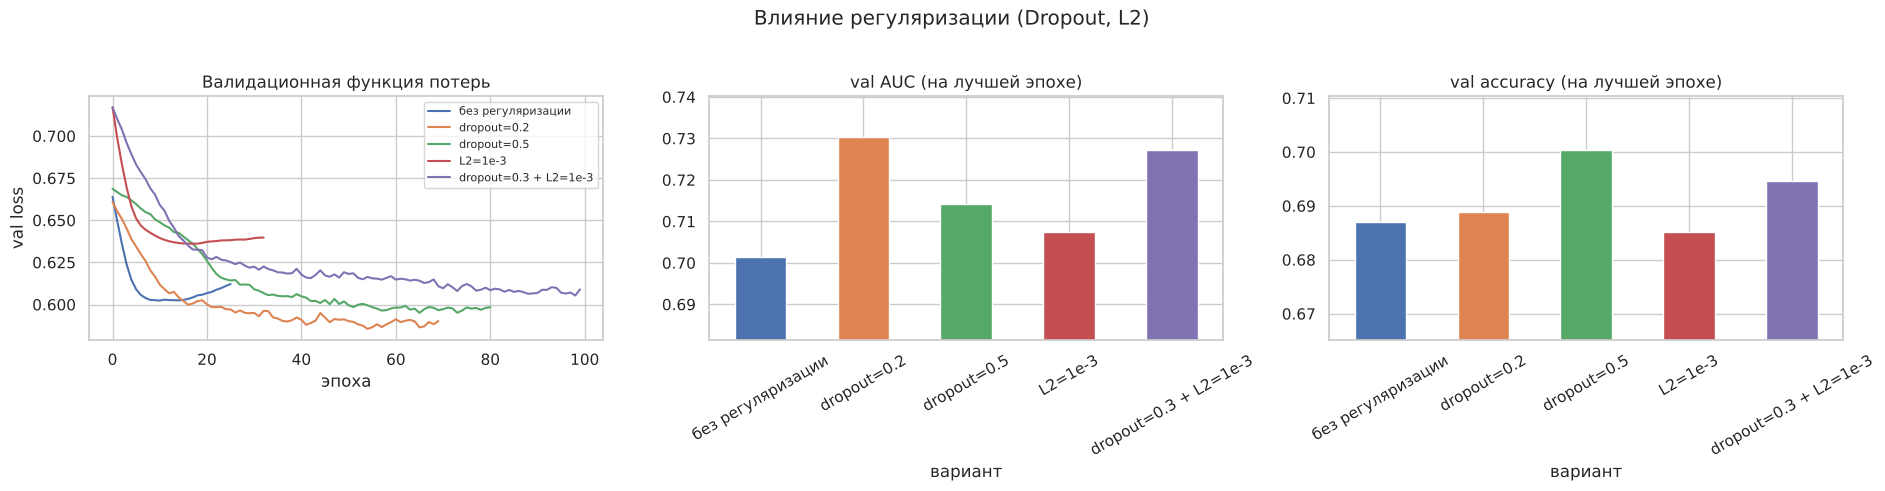

,эпох выполнено,лучшая эпоха,train loss,val loss,train acc,val acc,val AUC,"время, с"
вариант,,,,,,,,
без регуляризации,26,11,0.5618,0.6023,0.7085,0.6870,0.7014,13.4027
dropout=0.2,70,55,0.5579,0.5855,0.7199,0.6889,0.7302,33.9557
dropout=0.5,81,66,0.5888,0.5950,0.6861,0.7004,0.7142,36.4595
L2=1e-3,33,18,0.5899,0.6360,0.7142,0.6851,0.7074,16.1690
dropout=0.3 + L2=1e-3,100,99,0.5835,0.6053,0.7004,0.6947,0.7273,45.0799


In [31]:
exp_reg, h_reg = experiment("regularization", {
    "без регуляризации": {"dropout": 0.0}, "dropout=0.2": {"dropout": 0.2}, "dropout=0.5": {"dropout": 0.5},
    "L2=1e-3": {"dropout": 0.0, "l2": 1e-3}, "dropout=0.3 + L2=1e-3": {"dropout": 0.3, "l2": 1e-3}})
plot_experiment(exp_reg, h_reg, "Влияние регуляризации (Dropout, L2)")
exp_reg

**Пояснение к блоку кода.** **Эксперимент 6 — регуляризация:** без регуляризации, Dropout 0.2 и 0.5, L2-штраф 10⁻³, комбинация Dropout 0.3 + L2.

**Вывод по графикам и таблице.** Без регуляризации сеть переобучается очень быстро: минимум val loss на 11-й эпохе (0.602), val AUC 0.701 — худший результат. Dropout 0.2 даёт лучший val AUC в группе (**0.730**, val loss 0.586, остановка на 55-й эпохе); Dropout 0.5 (0.714) и L2 (0.707, val loss 0.636) хуже: слишком сильный Dropout замедляет обучение, а L2 с таким коэффициентом заметно увеличивает потери. Комбинация Dropout 0.3 + L2 даёт 0.727, но не успевает завершить обучение (лучшая эпоха 99). Вывод: умеренный Dropout (0.2–0.3) — простой и эффективный способ борьбы с переобучением.

### Выбор итоговой конфигурации и оценка на тесте

Из всех экспериментов выбирается конфигурация с наибольшим AUC на валидационной выборке, после чего она **один раз** оценивается на тестовой выборке. Выбор по лучшему из десятков запусков на одной небольшой валидационной выборке (524 образца) неизбежно оптимистичен, и разница между верхними конфигурациями (0.02 по AUC) сопоставима с шумом; это учитывается в сравнении ниже.

Выбрана конфигурация (по максимальному val AUC): arch/256-128-64-32
Параметры: {'batch_size': 32, 'hidden': (256, 128, 64, 32)}


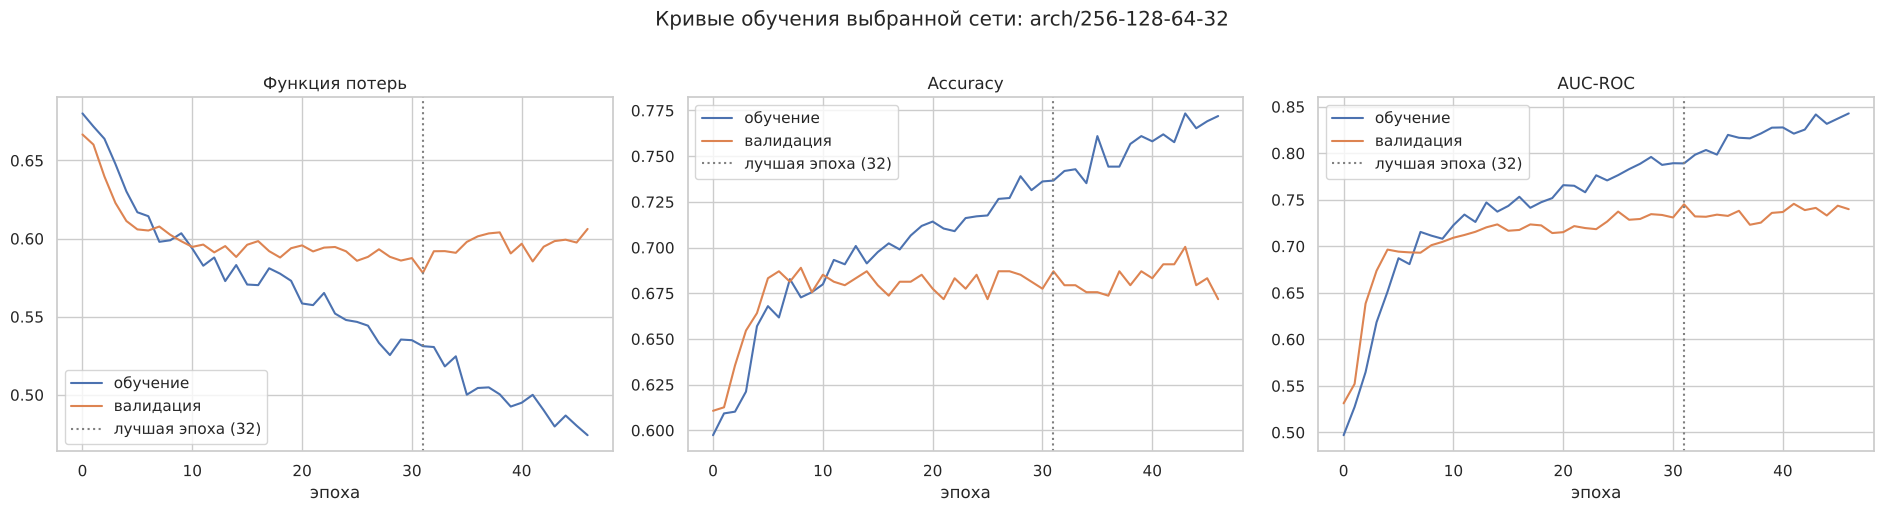

,эпох выполнено,лучшая эпоха,train loss,val loss,train acc,val acc,val AUC,"время, с",вариант
эксперимент,,,,,,,,,
arch/256-128-64-32,47,32,0.5311,0.5781,0.7366,0.6870,0.7451,28.5826,256-128-64-32
batch/batch=16,100,86,0.5503,0.5804,0.7075,0.6908,0.7332,66.4057,batch=16
regularization/dropout=0.2,70,55,0.5579,0.5855,0.7199,0.6889,0.7302,33.9557,dropout=0.2
regularization/dropout=0.3 + L2=1e-3,100,99,0.5835,0.6053,0.7004,0.6947,0.7273,45.0799,dropout=0.3 + L2=1e-3
optimizer/adam lr=1e-2,55,40,0.5591,0.5895,0.7104,0.6851,0.7271,27.6855,adam lr=1e-2
batch/batch=8,61,46,0.5728,0.5845,0.7032,0.6756,0.7266,74.5742,batch=8
arch/128-64-32,62,47,0.5462,0.5853,0.7171,0.6966,0.7255,33.6072,128-64-32
arch/64-32,73,58,0.5628,0.5870,0.7032,0.7023,0.7227,31.7144,64-32


In [32]:
all_rows = pd.DataFrame([v[2] for k, v in RUNS.items() if not k.startswith("base_200")]).set_index("эксперимент")
top = all_rows.sort_values("val AUC", ascending=False).head(8)
best_run = top.index[0]
print("Выбрана конфигурация (по максимальному val AUC):", best_run)
print("Параметры:", {k: v for k, v in RUNS[best_run][3].items()})
best_model = RUNS[best_run][0]
best_hist = RUNS[best_run][1]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
bb = RUNS[best_run][2]["лучшая эпоха"] - 1
for ax, (tr_c, va_c, title) in zip(axes, [("loss", "val_loss", "Функция потерь"), ("accuracy", "val_accuracy", "Accuracy"), ("auc", "val_auc", "AUC-ROC")]):
    ax.plot(best_hist[tr_c], label="обучение"); ax.plot(best_hist[va_c], label="валидация")
    ax.axvline(bb, color="gray", ls=":", label=f"лучшая эпоха ({bb+1})"); ax.set_xlabel("эпоха"); ax.set_title(title); ax.legend()
plt.suptitle(f"Кривые обучения выбранной сети: {best_run}", y=1.02); plt.tight_layout(); plt.show()
top

**Пояснение к блоку кода.** По результатам всех экспериментов (без 200-эпохальной демонстрации) выбирается конфигурация с наибольшим AUC на валидации; печатаются её параметры, кривые обучения (функция потерь, Accuracy, AUC на обучении и валидации, штриховая линия — лучшая эпоха) и таблица 8 лучших запусков.

**Вывод.** Выбрана сеть с архитектурой **256-128-64-32** (ReLU, Dropout 0.3, Adam 0.001, батч 32): val AUC 0.745, лучшая эпоха 32. По графикам видно расхождение обучающей и валидационной кривых: AUC на обучении растёт до 0.84, на валидации остаётся около 0.74, функция потерь на валидации после 32-й эпохи начинает расти — ранняя остановка вовремя возвращает веса лучшей эпохи. Из таблицы видно, что восемь лучших конфигураций различаются по val AUC всего на 0.02 (0.723–0.745), то есть выбор «лучшей» между ними частично определяется случайностью, и надёжный вывод даст только проверка на нескольких разбиениях (раздел 6).

In [33]:
nn_scores_test = best_model.predict(Xs_test, verbose=0).ravel()
nn_pred_test = (nn_scores_test >= 0.5).astype(int)
nn_test = metrics_from(y_test, nn_pred_test, nn_scores_test)
print("Нейронная сеть, тест:", {k: round(v, 4) for k, v in nn_test.items()})

Нейронная сеть, тест: {'Accuracy': 0.6616, 'Precision': 0.6181, 'Recall': 0.3477, 'F1': 0.445, 'AUC-ROC': 0.6409}


**Пояснение к блоку кода.** Выбранная сеть **однократно** оценивается на тестовой выборке: прогнозируются вероятности класса 1, класс определяется по порогу 0.5, считаются все пять метрик.

**Вывод.** Нейронная сеть на тесте: Accuracy 0.662, Precision 0.618, Recall 0.348, F1 0.445, AUC-ROC 0.641. Это заметно ниже val AUC (0.745): оценка на валидации была оптимистичной (выбор лучшей из многих конфигураций + особенности небольшой валидационной выборки).

### Мониторинг обучения в TensorBoard

Каждый запуск обучения записывал журналы (loss, accuracy, AUC на обучающей и валидационной выборках по эпохам) в папку `logs/<эксперимент>/<вариант>`; всего записано 28 запусков. Для просмотра нужно выполнить в терминале VS Code (в папке с ноутбуком) команду `tensorboard --logdir logs` и открыть в браузере адрес `http://localhost:6006` (в самом ноутбуке можно использовать магическую команду `%load_ext tensorboard` и `%tensorboard --logdir logs`). Папка `logs` приложена к работе.

Ниже — снимок интерфейса TensorBoard (вкладка «Time Series / Scalars») для трёх запусков: базовая сеть, обученная 200 эпох (`base_200_epochs`), базовая сеть с ранней остановкой (`batch/batch=32`) и выбранная сеть `arch/256-128-64-32`.

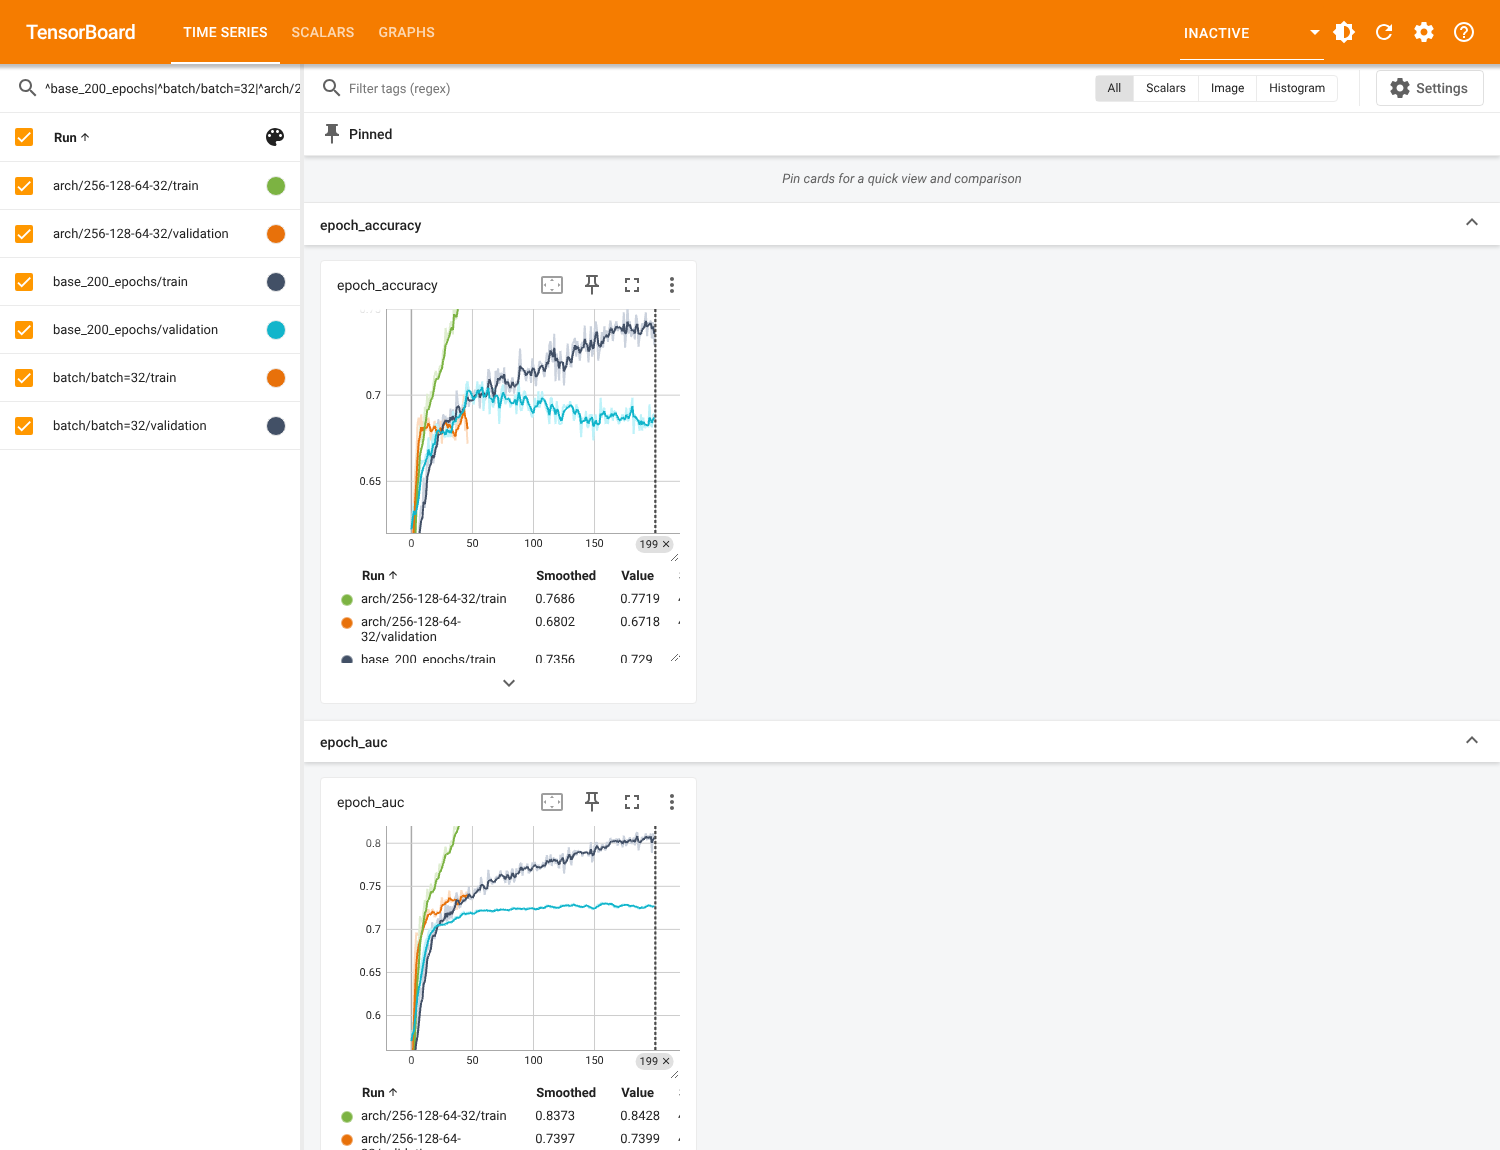

**Вывод по снимку.** В TensorBoard для каждого запуска две кривые — `train` и `validation` (разные цвета); по горизонтали — эпохи, по вертикали — метрика (`epoch_accuracy`, `epoch_auc`, `epoch_loss`). Видно ровно то, что показали графики выше: у 200-эпохальной сети кривые обучения (`train`) продолжают расти (AUC до 0.8 и выше), тогда как валидационные (`validation`) выходят на плато около 0.72–0.73 и далее не растут — это признак переобучения. Запуски с ранней остановкой обрываются раньше (кривые короче), а более глубокая сеть 256-128-64-32 быстрее набирает метрику на обучении, но на валидации (AUC ≈ 0.74) расходится с обучающей кривой уже к 30-й эпохе. TensorBoard удобен тем, что позволяет сравнивать десятки запусков на одном графике, включать сглаживание кривых и скрывать лишние запуски фильтром по имени.

## 6. Сравнительный анализ

Сравниваются лучшие модели всех методов (с подобранными гиперпараметрами) на **тестовой выборке**, которая не участвовала ни в обучении, ни в подборе параметров. Для обоснования вывода дополнительно приводятся доверительные интервалы, результаты на 20 разных разбиениях и анализ порога классификации.

In [34]:
final_models = {"GaussianNB": TUNED["GaussianNB"].best_estimator_, "MultinomialNB": TUNED["MultinomialNB"].best_estimator_,
                "ComplementNB": TUNED["ComplementNB"].best_estimator_, "BernoulliNB": TUNED["BernoulliNB"].best_estimator_,
                "Decision Tree": TUNED["Decision Tree"].best_estimator_, "LDA": TUNED["LDA"].best_estimator_,
                f"SVM ({best_kernel})": TUNED["SVM"].best_estimator_, "kNN": TUNED["kNN"].best_estimator_}

test_scores = {n: get_scores(m, X_test) for n, m in final_models.items()}
test_pred = {n: m.predict(X_test) for n, m in final_models.items()}
test_scores["Нейронная сеть"] = nn_scores_test; test_pred["Нейронная сеть"] = nn_pred_test
test_scores["Dummy"] = get_scores(dummy, X_test); test_pred["Dummy"] = dummy.predict(X_test)

res = pd.DataFrame({n: metrics_from(y_test, test_pred[n], test_scores[n]) for n in test_scores}).T
cv_auc = {**{n: TUNED[n.split(" (")[0] if not n.startswith("SVM") else "SVM"].best_score_ for n in final_models}}
res["CV AUC (подбор)"] = pd.Series(cv_auc)
res.loc["Нейронная сеть", "CV AUC (подбор)"] = RUNS[best_run][2]["val AUC"]
res = res.sort_values("AUC-ROC", ascending=False)
res

,Accuracy,Precision,Recall,F1,AUC-ROC,CV AUC (подбор)
Нейронная сеть,0.6616,0.6181,0.3477,0.4450,0.6409,0.7451
SVM (rbf),0.6433,0.5671,0.3633,0.4429,0.6341,0.7042
Decision Tree,0.6311,0.5461,0.3242,0.4069,0.6202,0.6287
kNN,0.6357,0.6393,0.1523,0.2461,0.6154,0.6711
GaussianNB,0.6143,0.5161,0.1875,0.2751,0.6090,0.5867
LDA,0.6098,0.0000,0.0000,0.0000,0.5480,0.4776
MultinomialNB,0.6098,0.0000,0.0000,0.0000,0.5412,0.4945
ComplementNB,0.5716,0.4528,0.4688,0.4607,0.5412,0.4945
BernoulliNB,0.5960,0.3200,0.0312,0.0569,0.5373,0.5533
Dummy,0.6098,0.0000,0.0000,0.0000,0.5000,NaN


**Пояснение к блоку кода.** Собираются итоговые модели всех методов (лучшие по кросс-валидации) и тривиальный классификатор; для каждого считаются метрики на **тестовой выборке**; нейросеть добавляется со своими тестовыми оценками. В таблице — Accuracy, Precision, Recall, F1, AUC-ROC (тест) и AUC, полученный при подборе гиперпараметров (кросс-валидация, для нейросети — валидационная выборка); строки упорядочены по AUC.

**Вывод по таблице.** Лучшие по AUC на тесте: нейронная сеть (0.641), SVM с RBF-ядром (0.634), дерево решений (0.620), kNN (0.615), GaussianNB (0.609). LDA, MultinomialNB, ComplementNB и BernoulliNB имеют AUC 0.537–0.548 — практически на уровне случайного угадывания. Accuracy лучших методов — 0.63–0.66 при 0.610 у тривиального классификатора, то есть выигрыш всего 2–5 процентных пунктов. LDA и MultinomialNB вообще не предсказывают класс 1 (Precision = Recall = 0) — их Accuracy равна доле класса 0. ComplementNB имеет наибольший Recall (0.469) и F1 (0.461), но за счёт низкой точности (Accuracy 0.572 — ниже тривиального классификатора). Разрыв между «CV AUC (подбор)» и тестовым AUC (например, SVM 0.704 против 0.634) объясняется как отбором лучшей конфигурации по кросс-валидации, так и случайностью конкретного разбиения (см. подраздел «Устойчивость сравнения»).

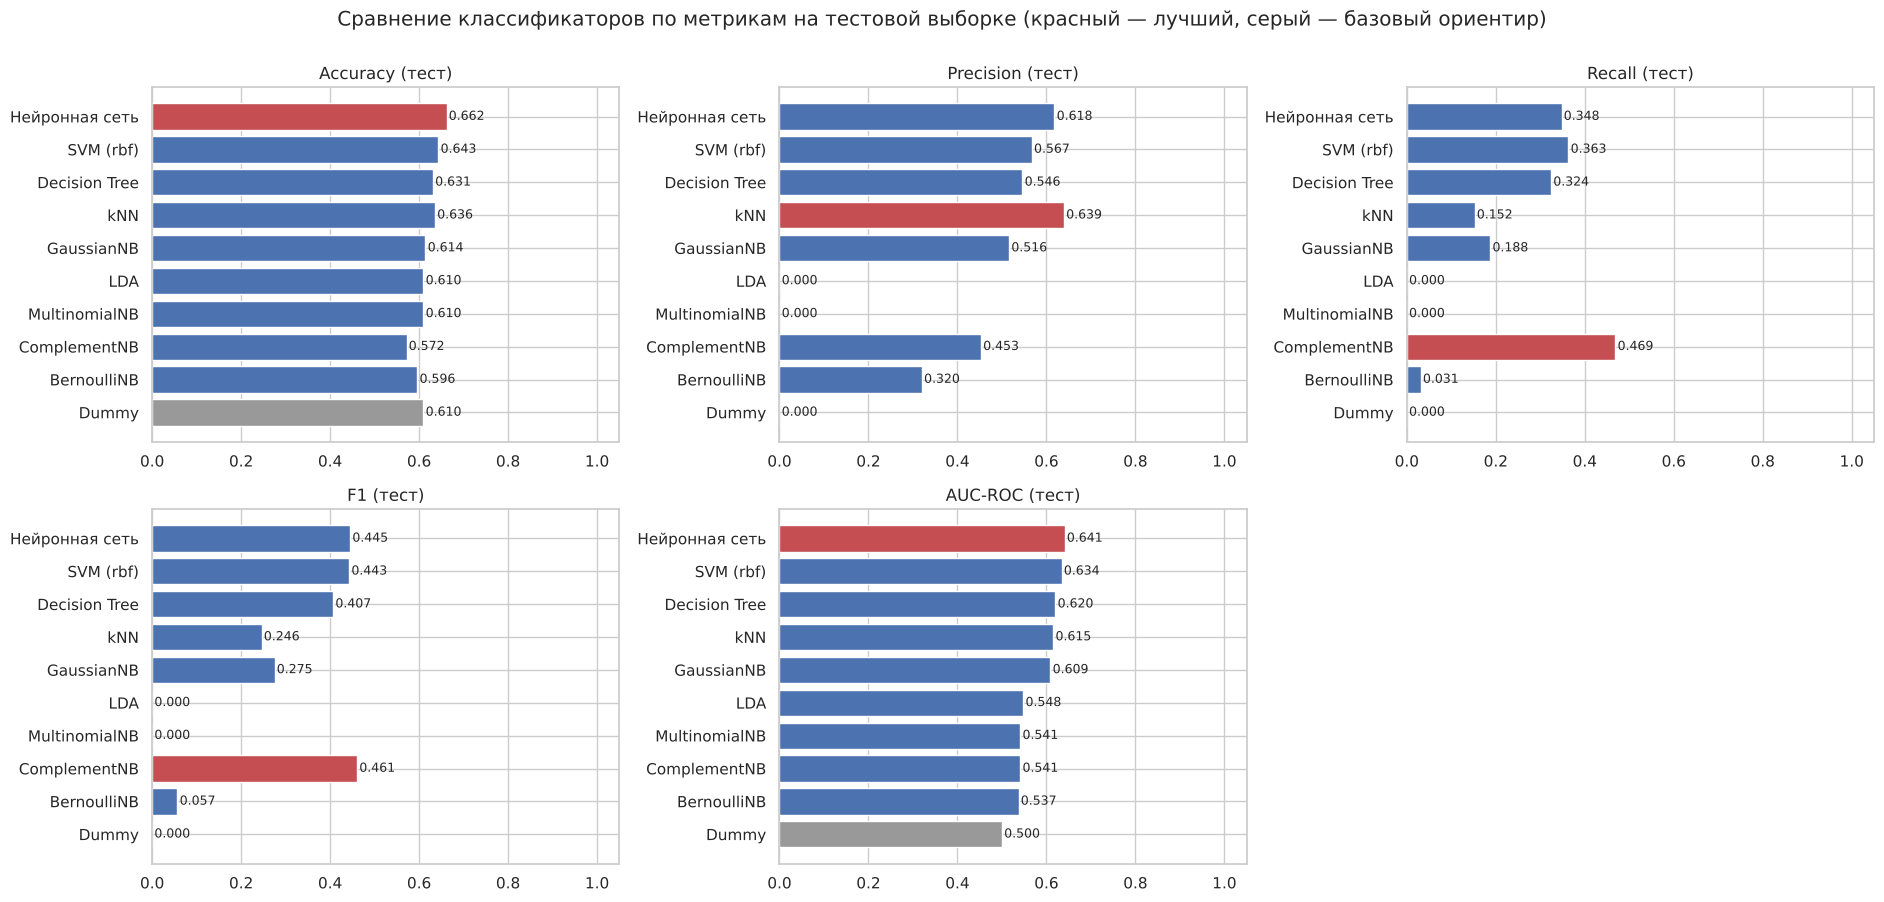

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(19, 9))
order = res.index.tolist()
for ax, m in zip(axes.ravel(), ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]):
    vals = res[m].reindex(order)
    colors = ["#999999" if n == "Dummy" else ("#C44E52" if n == vals.idxmax() else "#4C72B0") for n in order]
    ax.barh(order[::-1], vals.values[::-1], color=colors[::-1])
    for i, v in enumerate(vals.values[::-1]): ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlim(0, 1.05); ax.set_title(m + " (тест)")
axes.ravel()[-1].axis("off")
plt.suptitle("Сравнение классификаторов по метрикам на тестовой выборке (красный — лучший, серый — базовый ориентир)", y=1.0)
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Столбчатые диаграммы для каждой метрики (Accuracy, Precision, Recall, F1, AUC-ROC) на тесте; красным выделен лучший метод по соответствующей метрике, серым — тривиальный классификатор.

**Вывод по диаграммам.** Лучшие значения: Accuracy — нейросеть (0.662), Precision — kNN (0.639, но при Recall всего 0.152), Recall — ComplementNB (0.469), F1 — ComplementNB (0.461) с небольшим отрывом от нейросети (0.445) и SVM (0.443), AUC — нейросеть (0.641). Единого лидера по всем метрикам нет: метрики измеряют разное, и методы выбирают разный компромисс между Precision и Recall. Наиболее сбалансированно выглядят нейросеть и SVM — у них одновременно высокие Accuracy, Precision, F1 и AUC. Методы, у которых Precision высока, но Recall очень мал (kNN, GaussianNB, BernoulliNB), предсказывают класс 1 крайне редко.

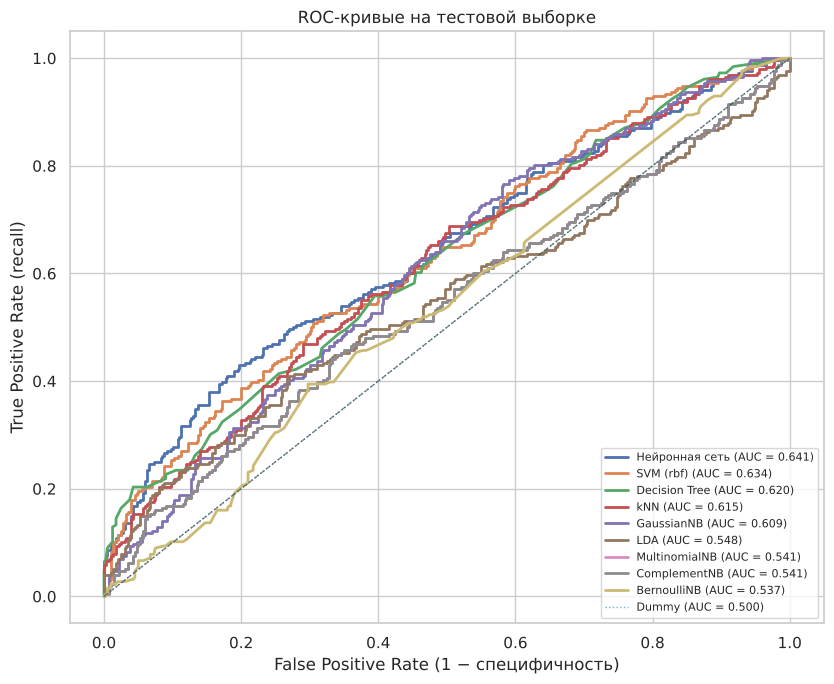

In [36]:
plt.figure(figsize=(8.5, 7))
for n in order:
    fpr, tpr, _ = roc_curve(y_test, test_scores[n])
    plt.plot(fpr, tpr, lw=2 if n != "Dummy" else 1, ls="-" if n != "Dummy" else ":", label=f"{n} (AUC = {res.loc[n, 'AUC-ROC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, alpha=.5)
plt.xlabel("False Positive Rate (1 − специфичность)"); plt.ylabel("True Positive Rate (recall)")
plt.title("ROC-кривые на тестовой выборке"); plt.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Строятся ROC-кривые всех моделей на тесте: по оси X — доля ложных срабатываний (FPR), по оси Y — доля найденных пригодных образцов (TPR) при всех возможных порогах; в легенде указана площадь под кривой. Диагональ — случайный классификатор.

**Вывод по графику.** Все кривые лежат вблизи диагонали, то есть классы разделяются плохо: у самых сильных моделей (нейросеть 0.641, SVM 0.634) кривые лишь немного выше диагонали, у LDA и наивных байесовских вариантов (AUC 0.537–0.548) практически сливаются с ней. Это согласуется с EDA: признаки по отдельности почти не различают классы, а сочетание признаков даёт лишь слабый сигнал.

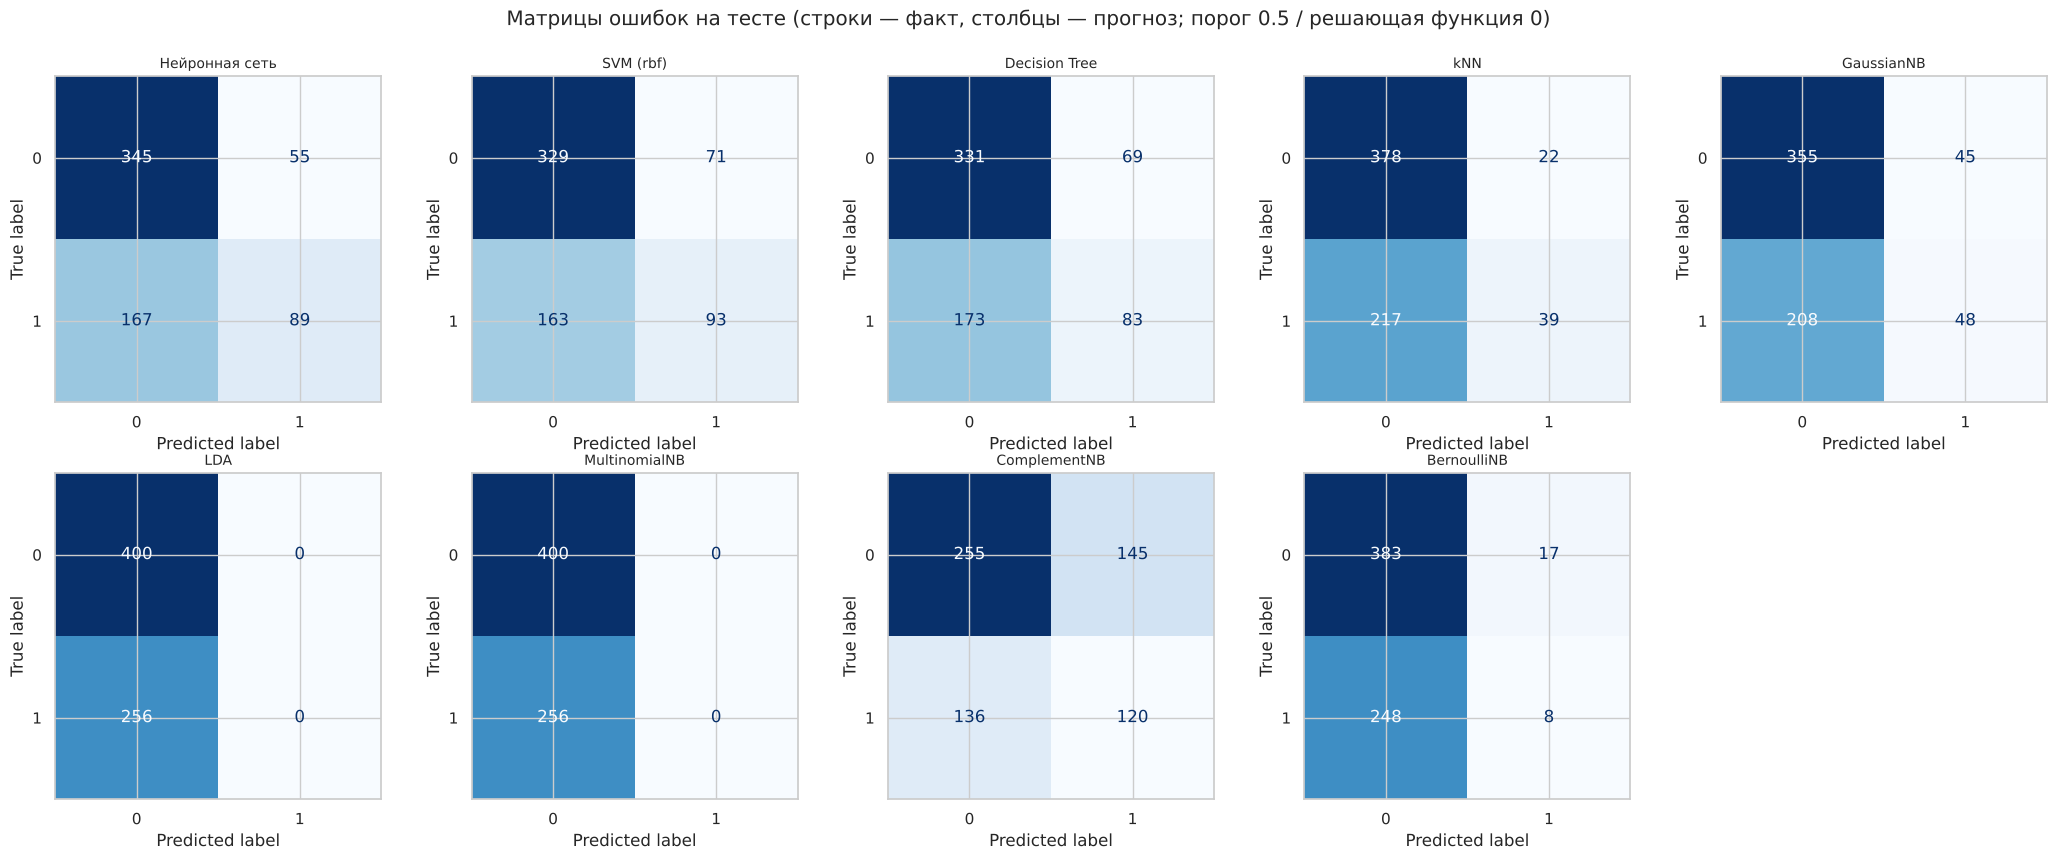

In [37]:
names = [n for n in order if n != "Dummy"]
fig, axes = plt.subplots(2, 5, figsize=(21, 8.5))
for ax, n in zip(axes.ravel(), names):
    ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred[n]), display_labels=["0", "1"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(n, fontsize=10)
for ax in axes.ravel()[len(names):]: ax.axis("off")
plt.suptitle("Матрицы ошибок на тесте (строки — факт, столбцы — прогноз; порог 0.5 / решающая функция 0)", y=1.0)
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Матрицы ошибок на тесте для всех моделей (строки — истинный класс, столбцы — предсказанный; 400 образцов класса 0 и 256 класса 1).

**Вывод по матрицам.** Все модели чаще ошибаются на классе 1 (пропускают пригодную воду): у нейросети 167 из 256 пригодных образцов отнесены к классу 0 (TP = 89, FP = 55), у SVM — 163 (TP = 93, FP = 71), у дерева — 173, у kNN — 217, у GaussianNB — 208. LDA и MultinomialNB относят все образцы к классу 0 (400 + 256 ошибок класса 1) — вырожденные классификаторы. ComplementNB, напротив, «находит» больше пригодных образцов (TP = 120), но ценой 145 ложных срабатываний. Такой перекос в сторону класса 0 — следствие дисбаланса классов и слабого сигнала.

In [38]:
rng = np.random.default_rng(SEED)
yt = y_test.values
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]
ci = {}
for n in names:
    s = test_scores[n]
    aucs = [roc_auc_score(yt[i], s[i]) for i in idx]
    accs = [accuracy_score(yt[i], test_pred[n][i]) for i in idx]
    ci[n] = {"AUC": res.loc[n, "AUC-ROC"], "AUC 95% ДИ": f"[{np.percentile(aucs, 2.5):.3f}; {np.percentile(aucs, 97.5):.3f}]",
             "Accuracy": res.loc[n, "Accuracy"], "Accuracy 95% ДИ": f"[{np.percentile(accs, 2.5):.3f}; {np.percentile(accs, 97.5):.3f}]"}
pd.DataFrame(ci).T

,AUC,AUC 95% ДИ,Accuracy,Accuracy 95% ДИ
Нейронная сеть,0.6409,[0.599; 0.684],0.6616,[0.628; 0.700]
SVM (rbf),0.6341,[0.589; 0.676],0.6433,[0.605; 0.681]
Decision Tree,0.6202,[0.576; 0.664],0.6311,[0.595; 0.668]
kNN,0.6154,[0.573; 0.659],0.6357,[0.601; 0.669]
GaussianNB,0.6090,[0.564; 0.655],0.6143,[0.576; 0.652]
LDA,0.5480,[0.501; 0.594],0.6098,[0.575; 0.646]
MultinomialNB,0.5412,[0.497; 0.588],0.6098,[0.575; 0.646]
ComplementNB,0.5412,[0.497; 0.588],0.5716,[0.535; 0.608]
BernoulliNB,0.5373,[0.491; 0.582],0.5960,[0.558; 0.633]


**Пояснение к блоку кода.** Для оценки неопределённости тестовых метрик методом бутстрепа (1 000 перевыборок тестовой выборки с возвращением) вычисляются 95%-е доверительные интервалы AUC и Accuracy для каждой модели.

**Вывод.** Интервалы шириной около 0.09 по AUC и 0.07 по Accuracy сильно перекрываются: нейросеть [0.599; 0.684], SVM [0.589; 0.676], дерево [0.576; 0.664], kNN [0.573; 0.659], GaussianNB [0.564; 0.655]. Различия между пятью лучшими методами на этом тесте **статистически не значимы**; уверенно можно утверждать лишь, что они лучше LDA и вариантов наивного Байеса Multinomial, Complement и Bernoulli (их интервалы AUC начинаются около 0.49–0.50, то есть включают случайное угадывание).

### Устойчивость сравнения: повторение на разных разбиениях

Тестовая выборка содержит всего 656 образцов, поэтому оценки метрик на ней заметно «шумят» (доверительные интервалы выше), а различия между лучшими методами меньше этого шума. Чтобы сделать вывод о лучшем методе более надёжным, все модели (с уже найденными гиперпараметрами) переобучаются и тестируются на нескольких разных разбиениях.

,Accuracy среднее,Accuracy СКО,Precision среднее,Precision СКО,Recall среднее,Recall СКО,F1 среднее,F1 СКО,AUC-ROC среднее,AUC-ROC СКО
Метод,,,,,,,,,,
SVM (rbf),0.6689,0.0137,0.6159,0.0280,0.4051,0.0327,0.4879,0.0272,0.6929,0.0175
Нейронная сеть,0.6730,0.0206,0.6430,0.0585,0.3832,0.0624,0.4752,0.0455,0.6849,0.0250
kNN,0.6518,0.0148,0.6799,0.0600,0.2037,0.0286,0.3129,0.0385,0.6556,0.0256
Decision Tree,0.6181,0.0174,0.5148,0.0299,0.4006,0.0375,0.4495,0.0287,0.6148,0.0259
GaussianNB,0.6246,0.0148,0.5470,0.0484,0.2316,0.0211,0.3249,0.0254,0.5942,0.0244
BernoulliNB,0.6132,0.0057,0.5467,0.0772,0.0535,0.0165,0.0969,0.0277,0.5513,0.0212
ComplementNB,0.5266,0.0177,0.3992,0.0222,0.4230,0.0324,0.4106,0.0257,0.5089,0.0196
MultinomialNB,0.6098,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5089,0.0196
LDA,0.6105,0.0018,0.3583,0.4660,0.0025,0.0046,0.0050,0.0091,0.5037,0.0152


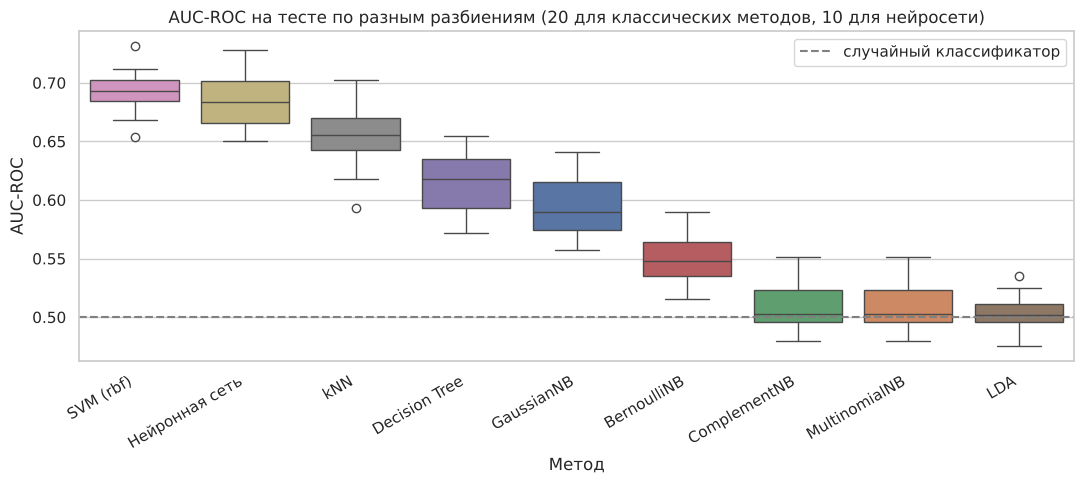

,доля разбиений с лучшим AUC,средний ранг (1 = лучший)
Метод,,
SVM (rbf),0.8000,1.2000
Нейронная сеть,0.2000,1.8000
BernoulliNB,0.0000,6.0000
ComplementNB,0.0000,7.9000
Decision Tree,0.0000,4.1000
LDA,0.0000,8.2000
GaussianNB,0.0000,4.7000
MultinomialNB,0.0000,7.9000
kNN,0.0000,3.2000


In [39]:
def split_data(seed):
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)

rep_rows = []
for seed in range(20):                       # 20 разных разбиений (random_state = 0 ... 19)
    Xa, Xb, ya, yb = split_data(seed)
    for n, m in final_models.items():
        mm = clone(m).fit(Xa, ya)            # гиперпараметры фиксированы по результатам подбора
        rep_rows.append({"seed": seed, "Метод": n, **evaluate(mm, Xb, yb)})

# нейронная сеть: выбранная конфигурация, 10 разбиений (обучение дольше)
cfg_best = {k: v for k, v in RUNS[best_run][3].items() if k != "batch_size"}
bs_best = RUNS[best_run][3]["batch_size"]
for seed in range(10):
    Xa, Xb, ya, yb = split_data(seed)
    pr = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]).fit(Xa)
    A, B = pr.transform(Xa), pr.transform(Xb)
    A_tr, A_val, ya_tr, ya_val = train_test_split(A, ya.values, test_size=0.2, stratify=ya.values, random_state=seed)
    mdl = build_model(seed=seed, **cfg_best)
    mdl.fit(A_tr, ya_tr, validation_data=(A_val, ya_val), epochs=100, batch_size=bs_best, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)])
    sc_ = mdl.predict(B, verbose=0).ravel()
    rep_rows.append({"seed": seed, "Метод": "Нейронная сеть", **metrics_from(yb, (sc_ >= 0.5).astype(int), sc_)})

rep = pd.DataFrame(rep_rows)
summary = rep.groupby("Метод")[["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]].agg(["mean", "std"])
summary.columns = [f"{a} {'среднее' if b == 'mean' else 'СКО'}" for a, b in summary.columns]
summary = summary.sort_values("AUC-ROC среднее", ascending=False)
display(summary)

order_rep = summary.index.tolist()
plt.figure(figsize=(11, 5))
sns.boxplot(data=rep, x="Метод", y="AUC-ROC", order=order_rep, hue="Метод", palette="deep", legend=False)
plt.axhline(0.5, color="gray", ls="--", label="случайный классификатор"); plt.xticks(rotation=30, ha="right")
plt.title("AUC-ROC на тесте по разным разбиениям (20 для классических методов, 10 для нейросети)"); plt.legend()
plt.tight_layout(); plt.show()

piv_auc = rep[rep["seed"] < 10].pivot(index="seed", columns="Метод", values="AUC-ROC")
wins = (piv_auc.rank(axis=1, ascending=False) == 1).mean().sort_values(ascending=False).to_frame("доля разбиений с лучшим AUC")
wins["средний ранг (1 = лучший)"] = piv_auc.rank(axis=1, ascending=False).mean()
wins

**Пояснение к блоку кода.** Чтобы сравнение не зависело от одного разбиения `random_state=42`, все методы с найденными гиперпараметрами переобучаются и оцениваются на 20 разных стратифицированных разбиениях (`random_state` 0…19); для нейросети (обучение дольше) — на первых 10 разбиениях. Строится таблица средних значений и стандартных отклонений метрик, диаграмма размаха AUC по разбиениям и таблица «доля разбиений с лучшим AUC / средний ранг» (по общим 10 разбиениям).

**Вывод по таблицам и графику.** Средний AUC на тесте: **SVM 0.693 ± 0.018**, нейросеть 0.685 ± 0.025, kNN 0.656 ± 0.026, дерево 0.615 ± 0.026, GaussianNB 0.594 ± 0.024, BernoulliNB 0.551, ComplementNB и MultinomialNB 0.509, LDA 0.504. Средняя Accuracy: нейросеть 0.673, SVM 0.669, kNN 0.652, GaussianNB 0.625, дерево 0.618 (тривиальный классификатор — 0.610). Средний F1: SVM 0.488, нейросеть 0.475, дерево 0.450 (у остальных ниже). SVM занимает первое место по AUC в 8 из 10 общих разбиений (средний ранг 1.2), нейросеть — в 2 из 10 (1.8). Различие SVM и нейросети по среднему AUC (0.008) меньше стандартного отклонения, но SVM устойчиво впереди. Важно, что на разбиении с `random_state=42` SVM получил AUC 0.634, тогда как в среднем 0.693 — это разбиение оказалось «невезучим» для SVM, поэтому ориентироваться стоит на усреднённые оценки. LDA и MultinomialNB в среднем не лучше случайного угадывания (AUC 0.50–0.51).

Классический метод с лучшим AUC на тесте: SVM (rbf)


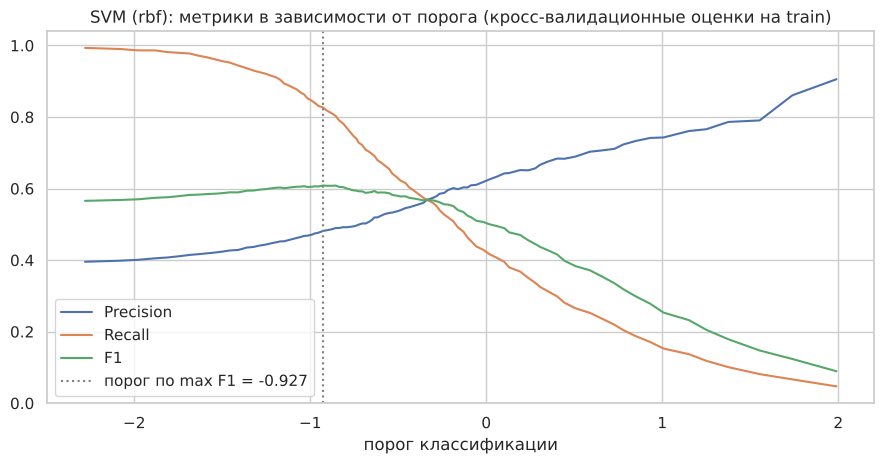

,Accuracy,Precision,Recall,F1,AUC-ROC
порог по умолчанию,0.6433,0.5671,0.3633,0.4429,0.6341
порог по max F1 (CV),0.5412,0.4466,0.7344,0.5554,0.6341


In [40]:
best_name = res.drop(index=["Dummy", "Нейронная сеть"]).index[0]      # лучший среди классических методов
print("Классический метод с лучшим AUC на тесте:", best_name)
# порог выбирается по кросс-валидационным оценкам на обучающей выборке (тест не используется)
est = final_models[best_name]
if True:
    m_name = "predict_proba" if hasattr(est, "predict_proba") else "decision_function"
    oof = cross_val_predict(clone(est), X_train, y_train, cv=cv, method=m_name, n_jobs=-1)
    oof = oof[:, 1] if oof.ndim == 2 else oof
    ths = np.quantile(oof, np.linspace(0.02, 0.98, 97))
    f1s = [f1_score(y_train, oof >= t) for t in ths]
    prs = [precision_score(y_train, oof >= t, zero_division=0) for t in ths]
    rcs = [recall_score(y_train, oof >= t) for t in ths]
    t_best = ths[int(np.argmax(f1s))]
    st = get_scores(est, X_test)
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(ths, prs, label="Precision"); ax.plot(ths, rcs, label="Recall"); ax.plot(ths, f1s, label="F1")
    ax.axvline(t_best, color="gray", ls=":", label=f"порог по max F1 = {t_best:.3f}")
    ax.set_xlabel("порог классификации"); ax.set_title(f"{best_name}: метрики в зависимости от порога (кросс-валидационные оценки на train)"); ax.legend()
    plt.tight_layout(); plt.show()
    thr_tab = pd.DataFrame({"порог по умолчанию": metrics_from(y_test, test_pred[best_name], st),
                            "порог по max F1 (CV)": metrics_from(y_test, (st >= t_best).astype(int), st)}).T
    display(thr_tab)

**Пояснение к блоку кода.** Исследуется влияние порога классификации на лучшую классическую модель (SVM). По кросс-валидационным оценкам на обучающей выборке строятся зависимости Precision, Recall и F1 от порога; выбирается порог, максимизирующий F1 (тест при выборе не используется), и затем модель с этим порогом оценивается на тесте.

**Вывод по графику и таблице.** При повышении порога Precision растёт, а Recall падает — классический компромисс. Порог по умолчанию (0) даёт Precision 0.567 при Recall 0.363; порог, максимизирующий F1 (≈ −0.93), увеличивает Recall до 0.734 и F1 до 0.555 (было 0.443), но снижает Precision до 0.447 и Accuracy до 0.541 (ниже тривиальных 0.610). AUC при этом не меняется (0.634), так как зависит только от ранжирования. Выбор порога должен определяться задачей: если важнее не пропустить пригодную воду — порог снижают, если главное — не объявить пригодной непригодную (опаснее с точки зрения безопасности питья), порог повышают и принимают более низкий Recall.

## Заключение

1. **Данные.** Датасет Water Potability: 3 276 образцов, 9 физико-химических признаков, бинарная цель `Potability` (39% пригодной воды, 61% непригодной). Пропуски в `ph` (15%), `Sulfate` (24%) и `Trihalomethanes` (5%) заполнены медианой внутри конвейера; признаки стандартизованы. Классы по отдельным признакам практически не различаются (корреляции с целью |r| ≤ 0.034, критерий Манна–Уитни не обнаружил значимых различий), признаки между собой почти не коррелируют (максимум 0.17).
2. **Методы и гиперпараметры.** Для пяти методов подобраны гиперпараметры кросс-валидацией по AUC-ROC и исследовано их влияние: у GaussianNB лучший `var_smoothing` ≈ 10⁻⁹ (слабая зависимость); у BernoulliNB критичен порог бинаризации (оптимум 1.0); у дерева оптимум — глубина 15 при `min_samples_leaf = 20` (мелкие деревья недообучаются, глубокие переобучаются); у LDA качество не зависит от сжатия (AUC ≈ 0.48); у SVM определяющим оказался тип ядра (RBF 0.704, полином 0.690, линейное 0.529, сигмоида 0.475) и параметры `C = 10`, `gamma = 0.1`; у kNN оптимальны `k = 35`, веса `distance`, евклидова метрика, а масштабирование критично (без него AUC 0.509, со стандартизацией 0.671).
3. **Нелинейность.** Линейные методы (LDA, линейный SVM) не лучше случайного угадывания, а нелинейные (RBF-SVM, kNN, дерево, нейросеть) дают AUC 0.62–0.69: зависимость класса от признаков нелинейна и локальна (по дереву решений, класс 1 чаще встречается при экстремальных значениях отдельных признаков, например при низких сульфатах).
4. **Нейронная сеть.** Построена сеть на TensorFlow/Keras (ReLU, сигмоида на выходе, binary cross-entropy, Adam, Dropout), проведены эксперименты по числу эпох (оптимум ≈ 30–60, дальше — переобучение), размеру батча, архитектуре (глубокая сеть 256-128-64-32 лучше мелкой), активациям (ReLU лучшая; sigmoid в скрытых слоях не обучается), оптимизаторам (Adam, разумный шаг) и регуляризации (Dropout 0.2–0.3). Обучение отслеживалось в TensorBoard.
5. **Сравнение.** На основном тестовом разбиении лучшие значения AUC у нейросети (0.641) и SVM (0.634), но 95%-е доверительные интервалы пяти лучших методов перекрываются. По 10–20 разбиениям: **SVM с RBF-ядром — AUC 0.693 ± 0.018, F1 0.488 (лучший)**, нейросеть — 0.685 ± 0.025 (Accuracy 0.673), kNN — 0.656, дерево — 0.615, GaussianNB — 0.594; LDA и MultinomialNB неотличимы от случайного угадывания (AUC 0.50–0.51).
6. **Вывод о лучшем подходе.** Для данного датасета лучший подход — **метод опорных векторов с RBF-ядром** (`C = 10`, `gamma = 0.1`, предварительная стандартизация): наивысший средний AUC и F1, первое место по AUC в 8 из 10 разбиений, высокая устойчивость, быстрое обучение и малое число гиперпараметров. Нейросеть сопоставима с ним по качеству (разница в AUC 0.008 меньше разброса), но требует существенно больше времени и подбора параметров, поэтому на таких небольших табличных данных её применение не оправдано. Дерево, kNN и GaussianNB заметно слабее; LDA и три из четырёх вариантов наивного Байеса (Multinomial, Complement, Bernoulli) для этих данных непригодны.
7. **Ограничения.** Абсолютное качество всех методов невелико: лучший AUC ≈ 0.69, Accuracy ≈ 0.67 (при 0.61 у тривиального классификатора), то есть предсказать пригодность воды по этим девяти показателям надёжно нельзя — вероятно, в данных недостаточно информации (имеющихся признаков мало для оценки безопасности воды). Это следует учитывать при практическом применении: модель не может заменять лабораторный анализ. Улучшить результат можно при помощи дополнительных признаков, а также настройкой порога классификации под цели задачи (при пороге по максимуму F1 Recall пригодной воды растёт с 0.36 до 0.73 ценой снижения точности).
8. **Точность оценок.** Доверительные интервалы на тесте (656 образцов) широки (около ±0.045 по AUC), поэтому небольшие различия между методами следует трактовать осторожно; проверка на нескольких разбиениях подтверждает ранжирование SVM > нейросеть > kNN > дерево > GaussianNB.

## Список источников

1. Dataset: *Water Quality (Water Potability)* [Электронный ресурс] // Kaggle. — https://www.kaggle.com/datasets/adityakadiwal/water-potability (дата обращения: 28.10.2026).
2. Pedregosa F. et al. *Scikit-learn: Machine Learning in Python* // Journal of Machine Learning Research. — 2011. — Vol. 12. — P. 2825–2830. Документация: https://scikit-learn.org/stable/supervised_learning.html (разделы «Naive Bayes», «Decision Trees», «Linear and Quadratic Discriminant Analysis», «Support Vector Machines», «Nearest Neighbors», «Model evaluation»).
3. Abadi M. et al. *TensorFlow: Large-Scale Machine Learning on Heterogeneous Systems* [Электронный ресурс]. — 2015. — https://www.tensorflow.org/ ; Chollet F. et al. *Keras*. — https://keras.io/ ; руководство по TensorBoard: https://www.tensorflow.org/tensorboard/get_started.
4. Hastie T., Tibshirani R., Friedman J. *The Elements of Statistical Learning*. — 2nd ed. — Springer, 2009 (гл. 4 «Linear Methods for Classification», гл. 9 «Additive Models, Trees», гл. 12 «Support Vector Machines», гл. 13 «Prototype Methods and Nearest-Neighbors»).
5. Goodfellow I., Bengio Y., Courville A. *Deep Learning*. — MIT Press, 2016 (гл. 6 «Deep Feedforward Networks», гл. 7 «Regularization», гл. 8 «Optimization»).
6. Kingma D. P., Ba J. *Adam: A Method for Stochastic Optimization* // ICLR 2015. — arXiv:1412.6980.
7. Fawcett T. *An introduction to ROC analysis* // Pattern Recognition Letters. — 2006. — Vol. 27, № 8. — P. 861–874.
8. Лекционные материалы курса «Машинное и глубокое обучение»: «Классификация. Нейронные сети. Кластеризация» (презентация из комплекта к лабораторной работе).
9. Документация pandas, NumPy, Matplotlib, Seaborn: https://pandas.pydata.org/docs/ , https://numpy.org/doc/ , https://matplotlib.org/ , https://seaborn.pydata.org/.